# Doughnut of Social and Planetary Boundaries  
  
Andrew L. Fanning and Kate Raworth published a [research paper in Nature](https://www.nature.com/articles/s41586-025-09385-1), that presents an updated framework and analysis of the **Doughnut of social and planetary boundaries** (the *Doughnut*), a visual tool for assessing global progress toward meeting human needs within the limits of the planet.  
  
The core finding is that despite a doubling of global **Gross Domestic Product (GDP)** between 2000 and 2022, the world is **"out of balance"** showing only modest social improvement alongside significant ecological degradation.  
  
In this assignment, we will recreate some visuals based on their official data published at [Zenodo](https://doi.org/10.5281/zenodo.15688961).  
  
---

> Grigoris Alexandrou <br />
> t8220004@aueb.gr <br />
> Department of Management Science and Technology <br />
> Athens University of Economics and Business  

## Setting the Scene  
For this assignment, I did the following steps:  
- I downloaded **uv** from [here](https://docs.astral.sh/uv/). UV is an extremely fast Python package and project manager, written in Rust.  
- I created a folder named *solution* with this file in it, and a subfolder *data* containing the data from zenodo.  
- Inside the *solution* folder, I run the following commands:
    - `uv init --bare`  
    - `uv python pin 3.13`  
    - `uv venv`  
    - `uv add pandas numpy jupyter plotly matplotlib altair scipy scikit-learn seaborn`
    - `uv run jupyter notebook .`
- And the project run at <http://localhost:8888/tree>  
- After that, I downloaded the [data](https://doi.org/10.5281/zenodo.15688961) and placed them in the *data* subfolder.
- Then, I created an *images* folder and an *outputs* folder to use them later on.
    

## Zenodo Data & Preparation
* Now that we have the data locally, let's investigate them.  
* I will start by importing some necessary modules.  

In [1]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.image as mpimg
os.makedirs("outputs", exist_ok=True)
os.makedirs("images", exist_ok=True)

* We have many csv files with the prefix **eco**. These belong to the **Ecological Domain**.
* And many csv files with the prefix **soc**. These belong to the **Social Domain**.
* Based on these csv files we will recreate some basic tables and plots.
* Specifically:
    * We will start with two tables:
        * The Social Foundation and Its Indicators of *Shortfall*
        * The Ecological Ceiling and Its Indicators of *Overshoot*
    * Then, we will proceed to the *Country Clusters Trellis Plots*
        * The clusters are: Bottom-40 / Middle-40 / Top-20
    * After that we will draw the *Sandwitch Plot*
    * Finally, we will try to reproduce the *Doughnut Plot*

## Assignment  

### The Social Foundation and Its Indicators of Shortfall
* We will start investigating the social foundation.
* The **Social Foundation** identifies the minimum social standards beneath which no-one should fall.
* The updated framework monitors *21 Indicators* across *12 Social Dimensions*. 

* First of all, we have to read all 12 csv files that belong to the social domain.
* We will create a function because we have to read both the social csv and the ecological csv files later on.

In [2]:
def read_csv_files(prefix):
    folder = "data"
    csv_files = glob.glob(os.path.join(folder, f"{prefix}-*.csv"))
    dfs = []
    for file in csv_files:
        try:
            df = pd.read_csv(file, encoding="utf-8")
        except UnicodeDecodeError:
            df = pd.read_csv(file, encoding="latin1")
        dfs.append(df)
    all_together_df = pd.concat(dfs, ignore_index=True)
    return all_together_df

In [3]:
social_foundation_df = read_csv_files("soc")
social_foundation_df

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
0,social,social cohesion,World,socialSupport,2000,5.697045e+09,11511.032635,NaN
1,social,social cohesion,World,socialSupport,2001,5.769703e+09,11642.650443,NaN
2,social,social cohesion,World,socialSupport,2002,5.842014e+09,11782.637162,NaN
3,social,social cohesion,World,socialSupport,2003,5.913980e+09,12066.579184,NaN
4,social,social cohesion,World,socialSupport,2004,5.986016e+09,12533.044784,NaN
...,...,...,...,...,...,...,...,...
2111,social,equality,Top-20,racialInequality,2018,1.049559e+09,52506.855542,NaN
2112,social,equality,Top-20,racialInequality,2019,1.055075e+09,53135.856588,NaN
2113,social,equality,Top-20,racialInequality,2020,1.058227e+09,50458.680722,NaN
2114,social,equality,Top-20,racialInequality,2021,1.059835e+09,53177.426297,NaN


* We can see that the table has many columns.
* One of the columns is `group`. Let's see the unique values of this column.

In [4]:
print(social_foundation_df['group'].unique())

['World' 'Bottom-40' 'Middle-40' 'Top-20']


* So, we have World, Bottom-40, Middle-40 and Top-20.
* These values mean that the measurement corresponds either globally (World) or Bottom 40% (poorest) or Middle 40% of the World, or Top 20% (richest) country.
* Since we want to examine the Social Foundation of the **World**, we should filter the table accordingly.

In [5]:
social_foundation_world = social_foundation_df.query("group == 'World'").copy()
social_foundation_world

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
0,social,social cohesion,World,socialSupport,2000,5.697045e+09,11511.032635,NaN
1,social,social cohesion,World,socialSupport,2001,5.769703e+09,11642.650443,NaN
2,social,social cohesion,World,socialSupport,2002,5.842014e+09,11782.637162,NaN
3,social,social cohesion,World,socialSupport,2003,5.913980e+09,12066.579184,NaN
4,social,social cohesion,World,socialSupport,2004,5.986016e+09,12533.044784,NaN
...,...,...,...,...,...,...,...,...
2042,social,equality,World,racialInequality,2018,7.479666e+09,16610.821317,NaN
2043,social,equality,World,racialInequality,2019,7.558226e+09,16900.084081,NaN
2044,social,equality,World,racialInequality,2020,7.631540e+09,16195.476629,NaN
2045,social,equality,World,racialInequality,2021,7.697245e+09,17037.452052,NaN


* What about the NaN values in the `value` column though?
* Is everything NaN?

In [6]:
print(social_foundation_world['value'].isna().all())

False


* Okay, so we have values (aka measurements) in the table.
* The NaN doesn't provide any information, so we should drop the rows and clean the table.

In [7]:
social_foundation_world.dropna(subset=['value'], inplace=True)
social_foundation_world

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
5,social,social cohesion,World,socialSupport,2005,6.058335e+09,12942.937170,20.469480
6,social,social cohesion,World,socialSupport,2006,6.130799e+09,13461.392711,20.885365
7,social,social cohesion,World,socialSupport,2007,6.203692e+09,13991.259635,23.907729
8,social,social cohesion,World,socialSupport,2008,6.277952e+09,14190.348582,24.203065
9,social,social cohesion,World,socialSupport,2009,6.353458e+09,13926.245251,22.283838
...,...,...,...,...,...,...,...,...
1950,social,equality,World,genderGapIndex,2018,7.479666e+09,16610.821317,0.363757
1951,social,equality,World,genderGapIndex,2019,7.558226e+09,16900.084081,0.356236
1952,social,equality,World,genderGapIndex,2020,7.631540e+09,16195.476629,0.352224
1953,social,equality,World,genderGapIndex,2021,7.697245e+09,17037.452052,0.350806


* The `domain` column, is *Social* because we have all the dimensions and indicators of the social domain.
* It doesn't provide any additional information.
* Same goes with the `group` column.
* Let's clean these up too.

In [8]:
social_foundation_world.drop(columns=['domain', 'group'], inplace=True)
social_foundation_world

,dimension,indicator,date,populationTotal,GNIperCap,value
5,social cohesion,socialSupport,2005,6.058335e+09,12942.937170,20.469480
6,social cohesion,socialSupport,2006,6.130799e+09,13461.392711,20.885365
7,social cohesion,socialSupport,2007,6.203692e+09,13991.259635,23.907729
8,social cohesion,socialSupport,2008,6.277952e+09,14190.348582,24.203065
9,social cohesion,socialSupport,2009,6.353458e+09,13926.245251,22.283838
...,...,...,...,...,...,...
1950,equality,genderGapIndex,2018,7.479666e+09,16610.821317,0.363757
1951,equality,genderGapIndex,2019,7.558226e+09,16900.084081,0.356236
1952,equality,genderGapIndex,2020,7.631540e+09,16195.476629,0.352224
1953,equality,genderGapIndex,2021,7.697245e+09,17037.452052,0.350806


* Just realised that the index is wrong. Let's reset that too.

In [9]:
social_foundation_world.reset_index(drop=True, inplace=True)
social_foundation_world

,dimension,indicator,date,populationTotal,GNIperCap,value
0,social cohesion,socialSupport,2005,6.058335e+09,12942.937170,20.469480
1,social cohesion,socialSupport,2006,6.130799e+09,13461.392711,20.885365
2,social cohesion,socialSupport,2007,6.203692e+09,13991.259635,23.907729
3,social cohesion,socialSupport,2008,6.277952e+09,14190.348582,24.203065
4,social cohesion,socialSupport,2009,6.353458e+09,13926.245251,22.283838
...,...,...,...,...,...,...
426,equality,genderGapIndex,2018,7.479666e+09,16610.821317,0.363757
427,equality,genderGapIndex,2019,7.558226e+09,16900.084081,0.356236
428,equality,genderGapIndex,2020,7.631540e+09,16195.476629,0.352224
429,equality,genderGapIndex,2021,7.697245e+09,17037.452052,0.350806


* Okay, so now let's proceed to the analysis.
* We want to calculate the shortfall (globally) as we said and provide insights.
* We will rely on the `value` column for each `indicator` and each indicator belongs to a `dimension`.
* Let's see the **dimensions** and the **indicators**.

In [10]:
dimension_indicators = social_foundation_world.groupby('dimension')['indicator'].unique().reset_index()
dimension_indicators

,dimension,indicator
0,connectivity,"[internet, publicTrans]"
1,education,"[adultLiteracy, secondarySchool]"
2,energy,"[energyAccess, energyIndoor]"
3,equality,[genderGapIndex]
4,food,"[undernourishment, foodInsecurity]"
5,health,"[under5death, UHCindex]"
6,housing,[urbanSlums]
7,income and work,"[societalPoverty, youthNEET]"
8,peace and justice,"[controlCorruption, homicideOver5]"
9,political voice,[govRegimes]


* One dimension of the Social Foundation is **Connectivity**. Its indicators are the *Internet* and *Public Transport*.
* But what does it mean *Internet* or *Public Transport*? 
* According to the documentation, the *Internet* means the percentage of the population **with access** to the internet.
* And *Public Transport* is the percentage of the population **with access** to public transport.
* This isn't though what we want. 
* We want to measure **Shortfall** aka the percentage of the population of the world that is *falling short* of the minimum acceptable standard.
* So we should transform the `value` column of these two indicators accordingly in order to show shortfall.
* The transformation formula is obvious: 100 - `value`.
* The percentage of the world population that doesn't have access to the internet (for example).

* Next up, we have **Education** dimension. The two indicators are *Adult Literacy* and *Secondary School*.
* *Adult Literacy* shows the adult population who are literate and *Secondary School* shows young adults (21-23 years old) who completed upper secondary education.
* Again, this is a kind of **access** not shortfall. The shortfall would be *Adult Population who are illiterate* not literate.
* And *young adults with incomplete upper secondary education*.
* We have to convert these indicators too.


* Next dimension is **Energy** with the indicators: *Energy Access* and *Energy Indoor*. 
* Just like before, here these two indicators measure **access** again, not shortfall.
* *Energy Access* is the population with access to electricity.
* *Energy Indoor* is the population with access to clean fuels and technologies for cooking heating and lighting.
* We should convert these too.

* Next dimension is **Equality** with one indicator: *genderGapIndex*.
* This index is indeed **shortfall** since it reports the score on the Gender Inequality Index.
* The global gap between women and men in terms of reproductive health empowerment and employment.

* Next dimension is **Food** with two indicators: *Undernourishment* and *Food Insecurity*.
* These indicators measure **shortfall** so there is no need for transformation.

* Next dimension is **Health** with indicators: *under5death* and *UHCindex*.
* The *under5death* reports the population living in countries without with under 5 mortality rate exceeding 25 per 1000 live births.
* The *UHCindex* is the Universal Health Coverage Index and reports the population living in countries without high coverage ofessential health services (UHCI score less than 60%).
* No need for transformation here either.

* Next dimension is **Housing** with *urbanSlums* indicator.
* This reports the population living in slums or informal settlements.
* This is **shortfall** too.

* Next dimension is **Income and Work** with *societalPoverty* and *youthNEET*.
* The first one is the population living below the societal poverty line.
* The second one is the population of the young people (15-24 years old) not in employment education or training.
* No need for transformation here. 

* Next dimension is **Peace and Justice** with: *controlCorruption* and *homicideOver5*.
* The *controlCorruption* reports the population stating that they perceive widespreadcorruption in government and business.
* The *homicideOver5* reports population living in countries with a homicide rate of 5+ per 100K.
* No need for transformation.

* Next dimension is **Political Voice** with indicator *govRegimes*.
* This reports population living in countries governed by an autocratic regime.
* This is shortfall, so no need for transformation.

* Next is **Social Cohesion** with indicators: *socialSupport* and *palma*.
* *socialSupport* reports the population stating that they are without someone to count on in times of trouble.
* *palma* reports the population living in countries with a Palma ration of 2 or more (the income share of the richest 10% of people relative to the poorest 40%).
* No need for any transformation.

* Last but not least is **Water** with indicators: *drinkingH2O* and *sanitation*.
* *drinkingH2O* reports population **with access** to safely managed drinking water.
* *sanitation* reports population **with access** to managed sanitation.
* So this needs to be transformed in order to measure **shortfall**.

* In conclusion, we should convert the indicators:
    * Internet
    * Public Transport
    * Adult Literacy
    * Secondary School
    * Energy Access
    * Energy Indoor
    * Drinking H2O
    * Sanitation

In [11]:
ACCESS_INDICATORS = ['internet', 'publicTrans', 'adultLiteracy', 'secondarySchool', 'energyAccess', 'energyIndoor', 'drinkingH2O', 'sanitation']
social_foundation_world['shortfall'] = np.where(
    social_foundation_world['indicator'].isin(ACCESS_INDICATORS),
    100 - social_foundation_world['value'],
    social_foundation_world['value']
)
social_foundation_world

,dimension,indicator,date,populationTotal,GNIperCap,value,shortfall
0,social cohesion,socialSupport,2005,6.058335e+09,12942.937170,20.469480,20.469480
1,social cohesion,socialSupport,2006,6.130799e+09,13461.392711,20.885365,20.885365
2,social cohesion,socialSupport,2007,6.203692e+09,13991.259635,23.907729,23.907729
3,social cohesion,socialSupport,2008,6.277952e+09,14190.348582,24.203065,24.203065
4,social cohesion,socialSupport,2009,6.353458e+09,13926.245251,22.283838,22.283838
...,...,...,...,...,...,...,...
426,equality,genderGapIndex,2018,7.479666e+09,16610.821317,0.363757,0.363757
427,equality,genderGapIndex,2019,7.558226e+09,16900.084081,0.356236,0.356236
428,equality,genderGapIndex,2020,7.631540e+09,16195.476629,0.352224,0.352224
429,equality,genderGapIndex,2021,7.697245e+09,17037.452052,0.350806,0.350806


* Now that we have the extra column `shortfall` with the correct (logically) values, we can move on.
* Now that I think about it, the `populationTotal` and `GNIperCap` column does not provide any additional information in this context.
* So we can drop these two columns.

In [12]:
social_foundation_world.drop(columns=['populationTotal', 'GNIperCap'], inplace=True)
social_foundation_world

,dimension,indicator,date,value,shortfall
0,social cohesion,socialSupport,2005,20.469480,20.469480
1,social cohesion,socialSupport,2006,20.885365,20.885365
2,social cohesion,socialSupport,2007,23.907729,23.907729
3,social cohesion,socialSupport,2008,24.203065,24.203065
4,social cohesion,socialSupport,2009,22.283838,22.283838
...,...,...,...,...,...
426,equality,genderGapIndex,2018,0.363757,0.363757
427,equality,genderGapIndex,2019,0.356236,0.356236
428,equality,genderGapIndex,2020,0.352224,0.352224
429,equality,genderGapIndex,2021,0.350806,0.350806


* Okay, now we can rely on the `date` column for information.
* We want to investigate the Social Foundation by analyzing the Shortfall for each indicator between the earliest and the latest observation year.
* This comparison will reveal the global trend in reducing human deprivation over the 2000 - 2022 period.
* In order to achieve this, we will group the data by `dimension` and `indicator` and extract the `shortfall` values corresponding to the minimum (`first`) and maximum (`last`) `date`.
* To analyze the trend in reducing human deprivation over the 2000-2022 period, we need to compare the earliest and latest observations for each indicator.


* We filter the dataset to keep only the rows where the date corresponds to either:
    - The minimum (earliest) date for each indicator, or
    - The maximum (latest) date for each indicator

* This will allow us to calculate the shortfall reduction between these two time points.

* I will create a function that keeps only the earliest and latest date of each indicator.
* I am doing this because we will do this two times: one with the social foundation and another one with the ecological ceiling.

In [13]:
def keep_min_max_dates(df):
    df = df[
        (df.groupby('indicator')['date'].transform('min') == df['date']) |
        (df.groupby('indicator')['date'].transform('max') == df['date'])
    ]
    df.reset_index(drop=True, inplace=True)
    return df

* Let's use the function for the social foundation now.

In [14]:
social_foundation_world = keep_min_max_dates(social_foundation_world)

* We do not need the `value` column anymore.
* Let's drop that and rename the `shortfall` column into `value`

In [15]:
social_foundation_world = (
    social_foundation_world
    .drop(columns=['value'])
    .rename(columns={'shortfall': 'value'})
)

* Let's round up to two decimal points the `value` column.
* Also, some values are less than 1. 
* This means that the upper measurement bound is 1. So to convert this to percentage (%) we have to multiply this by 100. 

In [16]:
mask = social_foundation_world['value'] < 1
social_foundation_world.loc[mask, 'value'] = (
    social_foundation_world.loc[mask, 'value'] * 100
)
social_foundation_world['value'] = social_foundation_world['value'].round(2)

* Let's create now the final table.
* The final table shows the dimensions sorted.
* Then the indicators (also sorted).
* The dates (earliest and latest).
* The values on the observed dates.
* We will do that again on a function to reuse it later.

In [17]:
def create_final_df(df):
    df = df.sort_values(['indicator', 'date']).reset_index(drop=True)

    first_obs = df.groupby('indicator').first().reset_index()
    last_obs = df.groupby('indicator').last().reset_index()

    first_obs = first_obs[['dimension', 'indicator', 'date', 'value']]
    last_obs = last_obs[['indicator', 'date', 'value']]

    final_table = first_obs.merge(last_obs, on='indicator', suffixes=('_first', '_last'))

    final_table = final_table[['dimension', 'indicator', 'date_first', 'date_last', 'value_first', 'value_last']]

    final_table = final_table.sort_values(['dimension', 'indicator']).reset_index(drop=True)

    columns = pd.MultiIndex.from_tuples([
        ('dimension', ''),
        ('indicator', ''),
        ('date', 'first'),
        ('date', 'last'),
        ('value', 'first'),
        ('value', 'last')
    ])

    final_table.columns = columns
    return final_table

* Let's use the helper function to our *social_foundation_world* dataframe.

In [18]:
final_table = create_final_df(social_foundation_world)
final_table

dimension          indicator  date        value       
                                         first  last  first   last
0        connectivity           internet  2000  2022  93.52  35.82
1        connectivity        publicTrans  2020  2020  52.71  52.71
2           education      adultLiteracy  2000  2022  23.13  16.15
3           education    secondarySchool  2000  2022  60.87  36.91
4              energy       energyAccess  2000  2022  21.71   8.51
5              energy       energyIndoor  2000  2022  50.49  25.92
6            equality     genderGapIndex  2000  2022  45.69  34.72
7                food     foodInsecurity  2015  2022  22.24  29.36
8                food   undernourishment  2000  2022  13.09   9.62
9              health           UHCindex  2000  2022  79.05  28.07
10             health        under5death  2000  2022  75.40  42.62
11            housing         urbanSlums  2000  2022  39.71  32.07
12    income and work    societalPoverty  2000  2022  84.92  72.51
13    income and work          youthNEET  2005  2022  24.97  20.31
14  peace and justice  controlCorruption  2005  2022  79.94  74.78
15  peace and justice      homicideOver5  2000  2022  28.45  19.52
16    political voice         govRegimes  2000  2022  46.64  70.76
17    social cohesion              palma  2000  2022  71.33  64.67
18    social cohesion      socialSupport  2005  2022  20.47  23.01
19              water        drinkingH2O  2000  2022  39.31  36.64
20              water         sanitation  2000  2022  66.31  41.17

* Okay, close enough to the final table. 
* In order to anyone understand what each indicator is, it should provide more information of what the inidcator measures.
* Let's create a mapping and change the values to be more user friendly.

In [19]:
final_table['dimension'] = final_table['dimension'].str.title()
indicator_mapping = {
    'internet': 'Population not accessing the internet',
    'publicTrans': 'Urban population lacking convenient access to public transport',
    'adultLiteracy': 'Adult population (aged 15+ years) who are illiterate',
    'secondarySchool': 'Young adult population (aged 21-23 years) with incomplete upper secondary education',
    'energyAccess': 'Population lacking access to electricity',
    'energyIndoor': 'Population lacking access to clean fuels and technologies for cooking, heating and lighting',
    'genderGapIndex': 'Population-weighted score on the Gender Inequality Index (global gap between women and men in terms of reproductive health, empowerment and employment)',
    'foodInsecurity': 'Population with moderate to severe food insecurity',
    'undernourishment': 'Population undernourished',
    'UHCindex': 'Population living in countries without high coverage ofessential health services (Universal Health Coverage Index score less than 60 out of 100)',
    'under5death': 'Population living in countries with under-5 mortality rate exceeding 25 per 1,000 live births',
    'urbanSlums': 'Urban population living in slums or informal settlements',
    'societalPoverty': 'Population living below the societal poverty line, set at half their country\'s median household income or at least $15 a day',
    'youthNEET': 'Population of young people (aged 15-24 years) not in employment, education or training',
    'controlCorruption': 'Population stating that they perceive widespread corruption in government and business',
    'homicideOver5': 'Population living in countries with a homicide rate of 5 or more per 100,000',
    'govRegimes': 'Population living in countries governed by an autocratic regime',
    'palma': 'Population living in countries with a Palma ratio of 2 or more (the income share of the richest 10% of people relative to the poorest 40%)',
    'socialSupport': 'Population stating that they are without someone to count on in times of trouble',
    'drinkingH2O': 'Population lacking access to safely managed drinking water',
    'sanitation': 'Population lacking access to safely managed sanitation'
}
social_final_table = final_table.copy()
final_table['indicator'] = final_table['indicator'].map(indicator_mapping)

* Now, we can use plotly to show the final table.
* Let's create a helper function that visualizes the table since we will use that again later for the ecological too.

In [20]:
def create_plotly_table(df):
    display_df = pd.DataFrame({
        "dimension": df[("dimension", "")],
        "indicator": df[("indicator", "")],
        "date_first": df[("date", "first")].astype(int),
        "date_last": df[("date", "last")].astype(int),
        "value_first": df[("value", "first")].round(2),
        "value_last": df[("value", "last")].round(2),
    })

    n = len(display_df)
    zebra = (["#ffffff", "#fafafa"] * (n // 2 + 1))[:n]

    fig = go.Figure(
        data=[
            go.Table(
                columnwidth=[130, 480, 70, 70, 70, 70],
                header=dict(
                    values=[
                        "<b>dimension</b>",
                        "<b>indicator</b>",
                        "<b>date<br>first</b>",
                        "<b>date<br>last</b>",
                        "<b>value<br>first</b>",
                        "<b>value<br>last</b>",
                    ],
                    align=["left", "left", "center", "center", "center", "center"],
                    fill_color="white",
                    line_color="#dddddd",
                    font=dict(family="Segoe UI, Arial", size=12),
                    height=30,
                ),
                cells=dict(
                    values=[
                        display_df["dimension"],
                        display_df["indicator"],
                        display_df["date_first"],
                        display_df["date_last"],
                        display_df["value_first"],
                        display_df["value_last"],
                    ],
                    align=["left", "left", "center", "center", "center", "center"],
                    fill_color=[zebra] * 6,
                    line_color="#dddddd",
                    font=dict(family="Segoe UI, Arial", size=11),
                    height=26,
                ),
            )
        ]
    )

    fig.update_layout(
        template=None,
        width=1000,
        height=900,
        margin=dict(l=0, r=0, t=20, b=0),
    )

    return fig


* Now, we can call the function with our table.
* And save the first output.

In [21]:
fig = create_plotly_table(final_table)
fig.show()
fig.write_image("outputs/1-soc-table.svg")

* Okay, at this point we reproduced the Table 1.
* But what does all of this mean? What is happening with the Social Foundation and Its Indicators of the Shortfall?

* So this table summarizes the **Social Foundation** of the Doughnut framework: a set of minimum social standards that every human should have access to in order to avoid deprivation.
* Each indicator reflects an essential human need or right.
* The **goal** is that no one should fall below these social thresholds, meaning that the share of the population in shortfall should approach 0%.

* Let's take a look at the table we produced.
* For each **Dimension** and each **Indicator** within that dimension, the table shows:
    * the **Earliest Year** with available data
    * the **Latest Year** with available data
    * the **Percentage of the World's Population in Shortfall** in the first and last year

* Shortfall is:
    * The percentage of people who do not have access (for the indicators that measure access)
    * or the percentage of people who are deprived (for indicators already expressed as deprivations)

* Example:
* For "Population not accessing the Internet" a shortfall of 93.52% in 2000 means:
* 93.52% of the world's population did not have access to the internet in 2000.
* By 2022 this decreased to 35.82%, an improvement but still implying that one in three people globally lack internet access today (2022 is the latest year, we do not have data for 2025).


* What Do All the Values Mean?
* Each row in the table corresponds to an essential human need and shows:
    * How many people globally were deprived at the first data point.
    * How many people globally are still (2022) deprived at the latest data point
* We can evaluate:
    * Whether global society is **improving**
    * How **fast** the improving occur
    * where **major inequalities and systemic failures persist**

* **Key Insights**
* The percentages shown represent the share of world population
* **Many Indicators Improve Over Time**
    * Internet Connectivity: 93.52% --> 35.82%
    * Electricity Access: 21.71% --> 8.51%
    * Under-5 Mortality: 75.40% --> 42.62%
    * These examples represent great global progress!
* **Some Improvements are not Fast Enough**
    * Even indicators that improved significantly still show massive global deprivation, far from the desired 0%.
    * In 2022:
        * 28.07% of the global population lives in countries without high health service coverage
        * 36.64% lack safety managed drinking water
        * 41.17% lack safety managed sanitation
        * 72.51% live below the societal poverty line
        * 74.78% perceive widespread corruption
        * 70.76% live under autocratic regimes
    * These values show that the world is nowhere near eliminating social shortfall.
* **Some Indicators Barely Improved or Worsened**
    * Food Insecurity Increased: 22.24% --> 29.36%
    * Corruption Shortfall remains extremely high: 79.94% --> 74.78%
    * Autocratic Governance grew worse: 46.64% --> 70.76%
    * Political Voice and Social Cohesion are stagnating or deteriorating.

* So this table shows **how far humanity is from achieving basic social justice and well-being**
* The Doughnut framework states that a safe and just world requires:
    * Zero Shortfall accross all social dimensions
    * Without overshooting ecological boundaries
* The table above makes it clear:
    * The world is not providing minimum social standards for billions of people
    * Deprivations remain widespread in nearly every social dimension
    * Progress is uneven and too slow to meet 2030 goals
    * Some indicators exhibit worsening global conditions

* As we said before we have a snapshot of global social deprivation trends (2000 - 2022).
* The table shows that despite improvements in some areas, the world is still far from ensuring basic human needs for all people.


### The Ecological Ceiling and Its Indicators of Overshoot
* Next, let's investivate the ecological ceiling.
* As we did in the previous example we will read all the csv files from the data folder.

In [22]:
eco_df = read_csv_files('eco')
eco_df

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value
0,ecological,climate change,global doughnut,World,co2_ppm,2000,NaN,NaN,368.96
1,ecological,climate change,global doughnut,World,co2_ppm,2001,NaN,NaN,370.57
2,ecological,climate change,global doughnut,World,co2_ppm,2002,NaN,NaN,372.58
3,ecological,climate change,global doughnut,World,co2_ppm,2003,NaN,NaN,375.14
4,ecological,climate change,global doughnut,World,co2_ppm,2004,NaN,NaN,376.95
...,...,...,...,...,...,...,...,...,...
1329,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2018,1.057622e+09,52596.852917,NaN
1330,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2019,1.063158e+09,53214.914280,NaN
1331,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2020,1.066320e+09,50530.945001,NaN
1332,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2021,1.067927e+09,53260.809722,NaN


* For the same reasons as before, we do not need the NaN values in the `value` column.
* We do not need the `domain`, `populationTotal` and `GNIperCap` columns.
* Also we should filter the `group` to World since we want to show the ecological ceiling globally.

In [23]:
eco_df_world = eco_df.query("group == 'World'").copy()
eco_df_world.dropna(subset=['value'], inplace=True)
eco_df_world.drop(columns=['domain', 'populationTotal', 'GNIperCap'], inplace=True)
eco_df_world.reset_index(drop=True, inplace=True)
eco_df_world

,dimension,type,group,indicator,date,value
0,climate change,global doughnut,World,co2_ppm,2000,368.960000
1,climate change,global doughnut,World,co2_ppm,2001,370.570000
2,climate change,global doughnut,World,co2_ppm,2002,372.580000
3,climate change,global doughnut,World,co2_ppm,2003,375.140000
4,climate change,global doughnut,World,co2_ppm,2004,376.950000
...,...,...,...,...,...,...
253,ozone depletion,global doughnut,World,totalOzone,2017,283.746475
254,ozone depletion,global doughnut,World,totalOzone,2018,286.320786
255,ozone depletion,global doughnut,World,totalOzone,2019,279.557846
256,ozone depletion,global doughnut,World,totalOzone,2020,281.959763


* The `type` is global doughnut to every row so we do not really need that too.

In [24]:
eco_df_world.drop(columns=['type', 'group'], inplace=True)
eco_df_world.reset_index(drop=True, inplace=True)
eco_df_world

,dimension,indicator,date,value
0,climate change,co2_ppm,2000,368.960000
1,climate change,co2_ppm,2001,370.570000
2,climate change,co2_ppm,2002,372.580000
3,climate change,co2_ppm,2003,375.140000
4,climate change,co2_ppm,2004,376.950000
...,...,...,...,...
253,ozone depletion,totalOzone,2017,283.746475
254,ozone depletion,totalOzone,2018,286.320786
255,ozone depletion,totalOzone,2019,279.557846
256,ozone depletion,totalOzone,2020,281.959763


* Let's think about what is it that we want for a second.
* The **Ecological Ceiling** defines the set of 9 **Planetary Boundaries** beyond which humanity's activities critically degrade Earth's life support systems.
* The *Doughnut Framework* uses **13 Indicators** across 9 dimensions to monitor **Overshoot** (the extent to which we are transgressing these safe limits).
* The critical ambition is for the world to operate entirely within this ceiling, meaning the overshoot for all ecological indicators must be 0% or less.
* Let's take a look at the dimensions and the indicators we have here.

In [25]:
eco_dimension_indicators = eco_df_world.groupby('dimension')['indicator'].unique().reset_index()
eco_dimension_indicators

,dimension,indicator
0,air pollution,[interhemAOD]
1,biodiversity breakdown,"[extinction1900, hanppGtC, species_footprint, ..."
2,chemical pollution,"[chemicalsMt, EUshare_hzdHealth]"
3,climate change,"[co2_ppm, erf_wm2, co2_footprint]"
4,freshwater disruption,"[blueDev, soilDev, blueH2O_footprint]"
5,land conversion,[forestAreaMKM2]
6,nutrient pollution,"[nitrogenMt, phosphorusMt, N_footprint, P_foot..."
7,ocean acidification,[omega_a]
8,ozone depletion,[totalOzone]


* For the dimension *Biodiversity breakdown* and the *Nutrient pollution* the indicators are not shown so let's see them.

In [26]:
print(eco_dimension_indicators.iloc[1]['indicator'])

['extinction1900' 'hanppGtC' 'species_footprint' 'hanpp_footprint']


In [27]:
print(eco_dimension_indicators.iloc[6]['indicator'])

['nitrogenMt' 'phosphorusMt' 'N_footprint' 'P_footprint']


* Now that we see all the indicators for the ecological dimensions, we can see that we have 20 indicators, not 13 as we said before.
* Why is that?
* While the full dataset contain more indicators, this analysis relies only on the subset of indicators that meet certain criteria for long term global monitoring.
* Our analysis right now is about the **World** (globally).
* So all the *footprint* indicators are excluded because they track consumption based enviromental burden. They are not time - series indicators of the global Earth System state.
* Also the *EUshare_hzdHealth* (regional indicator) is excluded because it does not meet the necessary criterion of having extensive international (global) coverage for the 2000 to 2022 time series monitoring.
* We have to clean a bit more the data from the table. 

In [28]:
EXCLUDED_INDICATORS = [
    'blueH2O_footprint', 'species_footprint', 'hanpp_footprint', 'N_footprint', 'P_footprint', 'co2_footprint', 'EUshare_hzdHealth'
]
eco_df_world = eco_df_world[~eco_df_world['indicator'].isin(EXCLUDED_INDICATORS)].copy()
eco_df_world

,dimension,indicator,date,value
0,climate change,co2_ppm,2000,368.960000
1,climate change,co2_ppm,2001,370.570000
2,climate change,co2_ppm,2002,372.580000
3,climate change,co2_ppm,2003,375.140000
4,climate change,co2_ppm,2004,376.950000
...,...,...,...,...
253,ozone depletion,totalOzone,2017,283.746475
254,ozone depletion,totalOzone,2018,286.320786
255,ozone depletion,totalOzone,2019,279.557846
256,ozone depletion,totalOzone,2020,281.959763


* Let's see our indicators one more time.

In [29]:
eco_dimension_indicators = eco_df_world.groupby('dimension')['indicator'].unique().reset_index()
eco_dimension_indicators

,dimension,indicator
0,air pollution,[interhemAOD]
1,biodiversity breakdown,"[extinction1900, hanppGtC]"
2,chemical pollution,[chemicalsMt]
3,climate change,"[co2_ppm, erf_wm2]"
4,freshwater disruption,"[blueDev, soilDev]"
5,land conversion,[forestAreaMKM2]
6,nutrient pollution,"[nitrogenMt, phosphorusMt]"
7,ocean acidification,[omega_a]
8,ozone depletion,[totalOzone]


* Let's inspect our dimensions and indicators now.
* First dimension is **Air Pollution** with the indicator *interhemAOD* 
    * which is the arithmetic error asymmetry between Earth's hemispheres of sunlight reaching the surface, owing to differences in atmospheric particle concetration (at most 0.1 inter-hemispheric difference in Aerosol Optical Depth).
* **Biodiversity Breakdown** has as indicators: *extinction1900* and *hanppGtC*.
    * The first one reports the rate of species extinctions per million species years (at most 10 E/MSY).
    * The second one reports human appropriation of net primary productivity, billions of tonnes of carbon per year (at most 10% of 55.9 Gt C).
* **Chemical Pollution** with indicator *chemicalsMt* 
    * which is the production of hazardous chemicals, millions of tonnes per year.
* **Climate Change** has two indicators: 
    * *co2_ppm* which is atmospheric carbon dioxide concentration, parts per million
    * *erf_wm2* which is the human induced radiative forcing at the top of the atmosphere, Watt per square meter.
* **Freshwater Disruption** has two indicators: 
    * *blueDev* aka the proportion of land are with human induced disturbance of blue water flow deviating from Holocene variabiity
    * *soilDev* aka the proportion of land area with root - zone soil moisture deviating from Holocene variablity.
* **Land Conversion** with indicator: *forestAreaMKM2* 
    * which means the area of forested land as proportion of forest covered land before human alteration.
* **Nutrient Pollution** has two indicators: 
    * *nitrogenMt* which is nitrogen applied to land as fertillizer, millions of tonnes per year
    * *phosphorusMt* which is phosphorus applied to land as fertilizer, millions of tonnes per year.
* **Ocean Acidification** with *omega_a*
    * which is the average saturation state of aragonite at the ocean surface.
* **Ozone Depletion** with *totalOzone*
    * which is the concentration of ozone in the stratosphere, Dosbone units.

* Now that we have a general idea about the indicators, let's proceed.
* First step would be to keep only the earliest and the latest day of the measurement per indicator
* Just like we did before with the Social Foundation.

In [30]:
eco_df_world = keep_min_max_dates(eco_df_world)
eco_df_world = eco_df_world.copy()

* Percect, now we will round up the `value` column to two decimals.

In [31]:
eco_df_world['value'] = eco_df_world['value'].round(2)
eco_df_world

,dimension,indicator,date,value
0,climate change,co2_ppm,2000,368.96
1,climate change,co2_ppm,2022,417.07
2,climate change,erf_wm2,2000,1.77
3,climate change,erf_wm2,2022,2.91
4,ocean acidification,omega_a,2000,2.99
5,ocean acidification,omega_a,2022,2.79
6,chemical pollution,chemicalsMt,2000,1186.00
7,chemical pollution,chemicalsMt,2017,2276.00
8,nutrient pollution,nitrogenMt,2000,132.24
9,nutrient pollution,nitrogenMt,2022,194.34


* Let's create the final table again.

In [32]:
eco_final_table = create_final_df(eco_df_world)
eco_final_table = eco_final_table.copy()
eco_final_table

dimension       indicator  date          value         
                                           first  last    first     last
0            air pollution     interhemAOD  2000  2022     0.08     0.08
1   biodiversity breakdown  extinction1900  2000  2022   100.00   100.00
2   biodiversity breakdown        hanppGtC  2000  2020    14.60    16.80
3       chemical pollution     chemicalsMt  2000  2017  1186.00  2276.00
4           climate change         co2_ppm  2000  2022   368.96   417.07
5           climate change         erf_wm2  2000  2022     1.77     2.91
6    freshwater disruption         blueDev  2000  2005     0.18     0.19
7    freshwater disruption         soilDev  2000  2014    15.43    19.25
8          land conversion  forestAreaMKM2  2000  2020    39.21    38.27
9       nutrient pollution      nitrogenMt  2000  2022   132.24   194.34
10      nutrient pollution    phosphorusMt  2000  2022    13.55    23.17
11     ocean acidification         omega_a  2000  2022     2.99     2.79
12         ozone depletion      totalOzone  2000  2021   284.30   284.58

* Close enough again.
* Let's add the description to each indicator

In [33]:
eco_final_table['dimension'] = eco_final_table['dimension'].str.title()
eco_indicator_mapping = {
    'interhemAOD': 'Arithmetic Error Asymmetry between Earth\'s hemispheres of sunlight reaching the surface, owing to differences in atmospheric particle concentration (at most 0.1 inter-hemispheric difference in Aerosol Optical Depth)',
    'extinction1900': 'Rate of species extinctions per million species years (at most 10 E/MSY)',
    'hanppGtC': 'Human appropriation of net primary productivity, billions of tonnes of carbon per year (at most 10% of 55.9 Gt C)',
    'chemicalsMt': 'Production of hazardous chemicals, millions of tonnes per year (at most 5% of the 1,200 Mt of total chemicals produced in year 2000)',
    'co2_ppm': 'Atmospheric carbon dioxide concentration, parts per million (at most 350 ppm CO2)',
    'erf_wm2': 'Human-induced radiative forcing at the top of the atmosphere, Watt per square metre (at most 1 W m**(-2))',
    'blueDev': 'Proportion of land area with human-induced disturbance of blue-water flow deviating from Holocene variability (at most 10.2%)',
    'soilDev': 'Proportion of land area with root-zone soil moisture deviating from Holocene variability (at most 11.1%)',
    'forestAreaMKM2': 'Area of forested land as a proportion of forest-covered land before human alteration (at least 75% of 64 million square kilometres)',
    'nitrogenMt': 'Nitrogen applied to land as fertilizer, millions of tonnes per year (at most 62 Mt per year)',
    'phosphorusMt': 'Phosphorus applied to land as fertilizer, millions of tonnes per year (at most 6.2 Mt per year)',
    'omega_a': 'Average saturation state of aragonite at the ocean surface (at least 80% of pre-industrial saturation state of 3.44 Ωarag)',
    'totalOzone': 'Concentration of ozone in the stratosphere, Dobson units (at most 5% decrease with respect to 1964-1980 value of 290 DU)'
}
eco_final = eco_final_table.copy()
eco_final_table['indicator'] = eco_final_table['indicator'].map(eco_indicator_mapping)
eco_final_table

dimension                                          indicator  \
                                                                                
0            Air Pollution  Arithmetic Error Asymmetry between Earth's hem...   
1   Biodiversity Breakdown  Rate of species extinctions per million specie...   
2   Biodiversity Breakdown  Human appropriation of net primary productivit...   
3       Chemical Pollution  Production of hazardous chemicals, millions of...   
4           Climate Change  Atmospheric carbon dioxide concentration, part...   
5           Climate Change  Human-induced radiative forcing at the top of ...   
6    Freshwater Disruption  Proportion of land area with human-induced dis...   
7    Freshwater Disruption  Proportion of land area with root-zone soil mo...   
8          Land Conversion  Area of forested land as a proportion of fores...   
9       Nutrient Pollution  Nitrogen applied to land as fertilizer, millio...   
10      Nutrient Pollution  Phosphorus applied to land as fertilizer, mill...   
11     Ocean Acidification  Average saturation state of aragonite at the o...   
12         Ozone Depletion  Concentration of ozone in the stratosphere, Do...   

    date          value           
   first  last    first     last  
0   2000  2022     0.08     0.08  
1   2000  2022   100.00   100.00  
2   2000  2020    14.60    16.80  
3   2000  2017  1186.00  2276.00  
4   2000  2022   368.96   417.07  
5   2000  2022     1.77     2.91  
6   2000  2005     0.18     0.19  
7   2000  2014    15.43    19.25  
8   2000  2020    39.21    38.27  
9   2000  2022   132.24   194.34  
10  2000  2022    13.55    23.17  
11  2000  2022     2.99     2.79  
12  2000  2021   284.30   284.58

* Now we have to show the table properly.

In [34]:
eco_fig = create_plotly_table(eco_final_table)
eco_fig.show()
eco_fig.write_image("outputs/2-eco-table.svg")

* We reproduced the Table 2 of the research paper.
* What's the meaning though?

* The **Ecological Ceiling** defines the **planetary boundaries** that must not be crossed if we want to maintain the stability of Earth's life-supporting systems.
* Crossing these boundaries indicate *ecological overshoot* where human activity exceeds safe planetary limits and disrupts Earth-system processes.
* This table lists the first and last available values for each ecological indicator.
* These values are later compared to the safe ecological boundary to assess overshoot.
* Each indicator is obviously linked to a planetary boundary.

* **Observations**
* Climate Change Indicators are Worsening since both Carbon Dioxide Concentration and Radiative Forcing increased.
* Hazardous Chemical Production almost doubled (1186 --> 2276 Mt)
* Nutrient Pollution has intensified: both nitrogen and phosphorus fertilizer use increased.
* Biodiversity Breakdown shows no improvement:
    * Species extinction rate stays extremely high 100 E/MSY
    * Human appropriation of net primary productivity increased 14.6 --> 16.8 GtC
    * The extinction rate is 900% above the boundary and is unchanged across two decades (2000 - 2022).
* Land Conversion: Forested area fell slightly (39.21 --> 38.27 Mkm squared)
* Freshwater Disruption:
    * Blue Water disruption stays nearly unchanged (0.18 --> 0.19)
    * Green Water Soil Moisture deviates increasingly (15.43 --> 19.25)
* Ocean Acidification worsened slightly: aragonite saturation 2.99 --> 2.79, moving further away from the safe boundary (3.44)
* Ozone Depletion stabilized: Ozone levels remain almost unchanged and within the boundary. This is the only ecological dimension that shows no worsening trend.

* **Overall**: 
* **Ecological Overshoot** is increasing almost everywhere.
* Humanity is Far outside the safe operating space.

### Country Clusters
* Now that we have seen the Social Foundation and Ecological Ceiling overall (globally) let's investigate based on the *country clusters*.
* Previously, we saw that the `group` column of the dataframes had these values apart from *World*: *Bottom 40*, *Middle 40*, *Top 20*.
* These are Country Clusters and represent:
    * The 40% of the world (poorest countries)
    * The 20% of the world (richest countries)
    * The 40% of the world (everything in between)
 

* Let's start with the **Ecological Overshoot**.
* We had the original table with all the ecological data.
* Let's see it again

In [35]:
eco_df

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value
0,ecological,climate change,global doughnut,World,co2_ppm,2000,NaN,NaN,368.96
1,ecological,climate change,global doughnut,World,co2_ppm,2001,NaN,NaN,370.57
2,ecological,climate change,global doughnut,World,co2_ppm,2002,NaN,NaN,372.58
3,ecological,climate change,global doughnut,World,co2_ppm,2003,NaN,NaN,375.14
4,ecological,climate change,global doughnut,World,co2_ppm,2004,NaN,NaN,376.95
...,...,...,...,...,...,...,...,...,...
1329,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2018,1.057622e+09,52596.852917,NaN
1330,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2019,1.063158e+09,53214.914280,NaN
1331,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2020,1.066320e+09,50530.945001,NaN
1332,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2021,1.067927e+09,53260.809722,NaN


* So now, instead of grouping by World, we want to exclude world.
* Also, let's drop the NaN values from the `value` column.

In [36]:
eco_df_clusters = eco_df[eco_df['group'] != 'World'].copy()
eco_df_clusters.dropna(subset=['value'], inplace=True)
eco_df_clusters.reset_index(drop=True, inplace=True)
eco_df_clusters

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value
0,ecological,climate change,national aggregate,Bottom-40,co2_footprint,2017,3.279187e+09,5022.645571,0.938904
1,ecological,climate change,national aggregate,Middle-40,co2_footprint,2017,3.183139e+09,15659.215592,4.256704
2,ecological,climate change,national aggregate,Top-20,co2_footprint,2017,9.857307e+08,51581.715835,11.650509
3,ecological,nutrient pollution,national aggregate,Bottom-40,N_footprint,2017,3.279187e+09,5022.645571,10.597806
4,ecological,nutrient pollution,national aggregate,Middle-40,N_footprint,2017,3.183139e+09,15659.215592,21.440116
5,ecological,nutrient pollution,national aggregate,Top-20,N_footprint,2017,9.857307e+08,51581.715835,32.406680
6,ecological,nutrient pollution,national aggregate,Bottom-40,P_footprint,2017,3.279187e+09,5022.645571,1.536249
7,ecological,nutrient pollution,national aggregate,Middle-40,P_footprint,2017,3.183139e+09,15659.215592,3.081177
8,ecological,nutrient pollution,national aggregate,Top-20,P_footprint,2017,9.857307e+08,51581.715835,4.168304
9,ecological,freshwater disruption,national aggregate,Bottom-40,blueH2O_footprint,2017,3.279187e+09,5022.645571,207.119042


* Perfect. Just to clarify: The analysis of global aggregates (Second Table) masks critical inequalities.
* This section (Country Clusters) investigates the distribution of enviromental responsibility and social need across 3 broad income clusters:
    * Poorest 40%
    * Middle 40%
    * Richest 20%

* Unlike the global analysis, the country cluster analysis relies heavily on **Consumption-Based Footprint Indicators**. This approach is necessary because:
    * Ecological planetary boundaries cannot be disaggregated to a national scale in a directly comparable manner
    * Consumption-based footprints allocate enviromental burdens (like pollution) to the final consumer, accounting for outsourcing via international trade
* Let's prepare the data for visualization.

* First of all, what is it that we want to show?
* We want to show **Ecological Overshoot**.
* The paper defines ecological overshoot mathematically as:
    * Overshoot = (Indicator - Baseline) / (Boundary - Baseline) - 1
* Where:
    * Indicator: the footprint value for the cluster (aka `value` column)
    * Baseline: pre-industrial Holocene level
    * Boundary: the downscaled per capita boundary used for the clusters
    * Output:
        * 0% overshoot = within boundary
        * 100% overshoot = 2x the boundary
        * 900% overshoot = 10x the boundary

* For our data, we have to compute: 
* Overshoot = (value / boundary) - 1
* Because for the cluster footprints:
    * baseline = 0
    * planetary boundary = per capita boundary
* And then multiply by 100 for percent.
* Final Formula: Overshoot = ((value / boundary) -1) * 100


* We have to create `boundary` column manually.
* Based on the research paper (specifically on their published data on Zenodo), I found the following boundaries for our indicators. 
* We will use these values to calculate the overshoot.

In [37]:
boundaries = {
    'co2_footprint':      0.95,
    'N_footprint':        8.5,
    'P_footprint':        0.85,
    'blueH2O_footprint':  384,
    'species_footprint':  0.51,
    'hanpp_footprint':    1.44
}

eco_df_clusters['boundary'] = eco_df_clusters['indicator'].map(boundaries)

eco_df_clusters['overshoot_percent'] = (
    (eco_df_clusters['value'] / eco_df_clusters['boundary'] - 1) * 100
)
eco_df_clusters.head()

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value,boundary,overshoot_percent
0,ecological,climate change,national aggregate,Bottom-40,co2_footprint,2017,3.279187e+09,5022.645571,0.938904,0.95,-1.168039
1,ecological,climate change,national aggregate,Middle-40,co2_footprint,2017,3.183139e+09,15659.215592,4.256704,0.95,348.074121
2,ecological,climate change,national aggregate,Top-20,co2_footprint,2017,9.857307e+08,51581.715835,11.650509,0.95,1126.369352
3,ecological,nutrient pollution,national aggregate,Bottom-40,N_footprint,2017,3.279187e+09,5022.645571,10.597806,8.50,24.680070
4,ecological,nutrient pollution,national aggregate,Middle-40,N_footprint,2017,3.183139e+09,15659.215592,21.440116,8.50,152.236664


* We have calculated the ecological overshoot, now let's display the trellis plot. 
* First of all let's clean the overshoot variables / values
* The `overshoot_percent` column gives the ecological overshoot as a percentage, where negative values mean that the cluster is still *within boundary*.
* For the visualisation, we will show only overshoot above the boundary, so all negative values should be set to 0 and store them in another column `overshoot_display`

In [38]:
eco_df_clusters['overshoot_display'] = eco_df_clusters['overshoot_percent'].copy()
eco_df_clusters.loc[eco_df_clusters['overshoot_display'] < 0, 'overshoot_display'] = 0
eco_df_clusters.head()

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value,boundary,overshoot_percent,overshoot_display
0,ecological,climate change,national aggregate,Bottom-40,co2_footprint,2017,3.279187e+09,5022.645571,0.938904,0.95,-1.168039,0.000000
1,ecological,climate change,national aggregate,Middle-40,co2_footprint,2017,3.183139e+09,15659.215592,4.256704,0.95,348.074121,348.074121
2,ecological,climate change,national aggregate,Top-20,co2_footprint,2017,9.857307e+08,51581.715835,11.650509,0.95,1126.369352,1126.369352
3,ecological,nutrient pollution,national aggregate,Bottom-40,N_footprint,2017,3.279187e+09,5022.645571,10.597806,8.50,24.680070,24.680070
4,ecological,nutrient pollution,national aggregate,Middle-40,N_footprint,2017,3.183139e+09,15659.215592,21.440116,8.50,152.236664,152.236664


* Now, we will select the indicators  and create a mapping with user friendly names

In [39]:
indicators = sorted(
    eco_df_clusters['indicator'].unique().tolist(),
    key=str.lower
)
indicator_names = {
    'blueH2O_footprint': 'Blue water footprint',
    'co2_footprint': 'Carbon footprint',
    'hanpp_footprint': 'HANPP footprint',
    'N_footprint': 'Nitrogen footprint',
    'P_footprint': 'Phosphorus footprint',
    'species_footprint': 'Species-loss footprint'
}

* Each cluster (bottom 40, middle 40 and top 20) will be displayed with a different color. 
* I will set the colors that we have in our assignment.
* Then let's create a 2x3 grid of subplots, one for each ecological footprint indicator.

In [40]:
trellis_colors = {
    'Bottom-40': '#FFD700',
    'Middle-40': '#C8A2C8',
    'Top-20': '#4682B4'
}

fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=[indicator_names[ind] for ind in indicators],
    vertical_spacing=0.15,
    horizontal_spacing=0.08,
    specs=[[{"type": "bar"}] * 3] * 2
)

* Now, for each indicator, we will subset the data, sort the income groups in the order Bottom --> Middle --> Top
* And add one bar per cluster to the corresponding subplot

In [41]:
cluster_order = pd.CategoricalDtype(
    ['Bottom-40', 'Middle-40', 'Top-20'], 
    ordered=True
)
eco_df_clusters['group'] = eco_df_clusters['group'].astype(cluster_order)

fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=[indicator_names[ind] for ind in indicators],
    vertical_spacing=0.15,
    horizontal_spacing=0.08,
    specs=[[{"type": "bar"}] * 3] * 2
)

for idx, indicator in enumerate(indicators):
    row = idx // 3 + 1
    col = idx % 3 + 1

    data_subset = eco_df_clusters.query("indicator == @indicator").copy()
    if data_subset.empty:
        continue

    data_subset = data_subset.sort_values('group')

    fig.add_trace(
        go.Bar(
            x=data_subset['group'],
            y=data_subset['overshoot_display'],
            marker_color=[trellis_colors[g] for g in data_subset['group']],
            name="Bottom-40",
            showlegend=(idx == 0),
            legendgroup="clusters",
            hovertemplate=(
                '<b>%{x}</b><br>Overshoot: %{y:.1f}%'
            )
        ),
        row=row, col=col
    )


* Finally, let's harmonise the y axis across all subplots and add categorical labels for the overshoot labels.

In [42]:
for r in [1, 2]:
    for c in [1, 2, 3]:
        fig.update_yaxes(
            range=[0, 1000],
            tickvals=[0, 200, 400, 600, 800, 1000],
            ticktext=['0%', '200%', '400%', '600%', '800%', '1000%'],
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=0.5,
            showline=True,
            linewidth=1,
            linecolor='lightgray',
            row=r, col=c
        )

fig.update_yaxes(title_text="Ecological overshoot", row=1, col=1)
fig.update_yaxes(title_text="Ecological overshoot", row=2, col=1)

fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=9),
    showline=True,
    linewidth=1,
    linecolor='lightgray',
    showgrid=False
)

fig.update_layout(
    title={
        'text': '<b>Country Clusters</b><br>',
        'font': {'size': 18, 'color': '#333', 'family': 'Arial'},
        'x': 0.5,
        'y': 0.95,
        'xanchor': 'center'
    },
    height=700,
    width=1200,
    showlegend=False,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.1,
        xanchor="center",
        x=0.5,
        font=dict(size=11)
    ),
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(family="Arial, sans-serif"),
    margin=dict(t=100, b=70, l=80, r=40)
)

fig.show()
fig.write_image("outputs/3-eco-country-clusters.svg")

* *Moving On ...*
* Next up, we will create a trellis plot that displays the social shortfall, for each indicator, for countries grouped according to their wealth.
* At the begining, we had a table. Let's see it.

In [43]:
social_foundation_df

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
0,social,social cohesion,World,socialSupport,2000,5.697045e+09,11511.032635,NaN
1,social,social cohesion,World,socialSupport,2001,5.769703e+09,11642.650443,NaN
2,social,social cohesion,World,socialSupport,2002,5.842014e+09,11782.637162,NaN
3,social,social cohesion,World,socialSupport,2003,5.913980e+09,12066.579184,NaN
4,social,social cohesion,World,socialSupport,2004,5.986016e+09,12533.044784,NaN
...,...,...,...,...,...,...,...,...
2111,social,equality,Top-20,racialInequality,2018,1.049559e+09,52506.855542,NaN
2112,social,equality,Top-20,racialInequality,2019,1.055075e+09,53135.856588,NaN
2113,social,equality,Top-20,racialInequality,2020,1.058227e+09,50458.680722,NaN
2114,social,equality,Top-20,racialInequality,2021,1.059835e+09,53177.426297,NaN


* Let's follow the same process as before.
* We want to keep everything, apart from World and drop NaN values

In [44]:
social_df_clusters = social_foundation_df[social_foundation_df['group'] != 'World'].copy()
social_df_clusters.dropna(subset=['value'], inplace=True)
social_df_clusters.reset_index(drop=True, inplace=True)
social_df_clusters

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
0,social,social cohesion,Bottom-40,socialSupport,2005,2.285372e+09,3232.607686,27.977830
1,social,social cohesion,Bottom-40,socialSupport,2006,2.327837e+09,3412.653654,28.416317
2,social,social cohesion,Bottom-40,socialSupport,2007,2.369725e+09,3588.415775,37.627323
3,social,social cohesion,Bottom-40,socialSupport,2008,2.411777e+09,3663.501012,33.000108
4,social,social cohesion,Bottom-40,socialSupport,2009,2.454747e+09,3815.923833,32.702104
...,...,...,...,...,...,...,...,...
1306,social,equality,Top-20,genderGapIndex,2018,1.049559e+09,52506.855542,0.123582
1307,social,equality,Top-20,genderGapIndex,2019,1.055075e+09,53135.856588,0.119965
1308,social,equality,Top-20,genderGapIndex,2020,1.058227e+09,50458.680722,0.115727
1309,social,equality,Top-20,genderGapIndex,2021,1.059835e+09,53177.426297,0.115340


* Since we had only 2017 date before, in the Ecological Overshoot.
* It makes sense that we take the same year here.
* However, if an indicator does not have a measurement that year, we will take the latest date.

In [45]:
TARGET_YEAR = 2017

target_dates = social_df_clusters.groupby('indicator')['date'].apply(
    lambda dates: TARGET_YEAR if TARGET_YEAR in dates.values else dates.max()
).reset_index()
target_dates.columns = ['indicator', 'target_date']

social_df_clusters = (
    social_df_clusters
    .merge(target_dates, on='indicator')
    .query('date == target_date')
    .drop(columns=['target_date'])
    .reset_index(drop=True)
)

* Just remembered that some indicators were in another format.
* Their format was a ratio: up to 1.0
* So, let's transform these values in order all of them to be in the same format.
* **Important**: We need to check that every `group` of the `indicator` has a value less than 1.
* Because as we can see below the *urbanSlums* at the Top-20 has a value 0.3 which is less than 1 but the other values are greater than 1. 
* This mean that the format is OK. Just the measurement is very low.

In [46]:
social_df_clusters[social_df_clusters['indicator'] == 'urbanSlums']

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
57,social,housing,Bottom-40,urbanSlums,2017,3.295114e+09,5037.432206,49.199764
58,social,housing,Middle-40,urbanSlums,2017,1.720404e+09,16951.097205,16.335741
59,social,housing,Top-20,urbanSlums,2017,7.718565e+08,54533.091741,0.363135


* Let's transform the values now.

In [47]:
indicators_to_scale = social_df_clusters.groupby('indicator')['value'].apply(
    lambda x: (x < 1).all()
)
indicators_to_scale = indicators_to_scale[indicators_to_scale].index.tolist()

social_df_clusters.loc[
    social_df_clusters['indicator'].isin(indicators_to_scale), 
    'value'
] *= 100
social_df_clusters['value'] = social_df_clusters['value'].round(2)

* We have to transform the `value` columns to the ones that measure access again, just like in the start of the notebook.

In [48]:
social_df_clusters['shortfall'] = np.where(
    social_df_clusters['indicator'].isin(ACCESS_INDICATORS),
    100 - social_df_clusters['value'],
    social_df_clusters['value']
)
social_df_clusters['value'] = social_df_clusters['shortfall']
social_df_clusters.drop(columns=['shortfall'], inplace=True)

* Let's define the order of the indicators and the plots
* And give indicators friendly names

In [49]:
indicators_ordered = [
    'govRegimes', 'foodInsecurity', 'genderGapIndex',
    'homicideOver5', 'adultLiteracy', 'palma',
    'secondarySchool', 'energyIndoor', 'energyAccess',
    'UHCindex', 'internet', 'publicTrans',
    'socialSupport', 'controlCorruption', 'urbanSlums',
    'societalPoverty', 'under5death', 'undernourishment',
    'drinkingH2O', 'sanitation', 'youthNEET'
]

indicator_names = {
    'govRegimes': 'Autocratic regimes',
    'foodInsecurity': 'Food insecurity',
    'genderGapIndex': 'Gender inequality',
    'homicideOver5': 'Homicide rate',
    'adultLiteracy': 'Illiteracy rate',
    'societalPoverty': 'Societal poverty',
    'secondarySchool': 'Incomplete secondary school',
    'energyIndoor': 'Lack of clean fuels indoors',
    'energyAccess': 'Lack of electricity',
    'UHCindex': 'Lack of health services',
    'internet': 'Lack of internet',
    'publicTrans': 'Lack of public transport',
    'socialSupport': 'Lack of social support',
    'controlCorruption': 'Perceptions of corruption',
    'urbanSlums': 'Slums or informal housing',
    'palma': 'Income inequality',
    'under5death': 'Under-5 mortality',
    'undernourishment': 'Undernourished',
    'drinkingH2O': 'Unsafe drinking water',
    'sanitation': 'Unsafe sanitation',
    'youthNEET': 'Youth NEET'
}

* Now let's prepare the grid with the subplots for each indicator

In [50]:
n_indicators = len(indicators_ordered)
n_rows = (n_indicators + 2) // 3

fig = make_subplots(
    rows=n_rows, 
    cols=3,
    subplot_titles=[indicator_names.get(ind, ind) for ind in indicators_ordered],
    vertical_spacing=0.10,
    horizontal_spacing=0.10,
    specs=[[{"type": "bar"}] * 3 for _ in range(n_rows)]
)


* We will add the bars for each indicator and for each cluster.
* For each indicator:
    * We filter the dataframe
    * Sort the clusters (Bottom - Middle - Top)
    * Show the shortfall per cluster

In [51]:
for idx, indicator in enumerate(indicators_ordered):
    row = idx // 3 + 1
    col = idx % 3 + 1
    
    data_subset = social_df_clusters[social_df_clusters['indicator'] == indicator].copy()
    
    if data_subset.empty:
        continue
    
    data_subset['group_order'] = data_subset['group'].map({
        'Bottom-40': 0,
        'Middle-40': 1,
        'Top-20': 2
    })
    data_subset = data_subset.sort_values('group_order')
    
    for _, row_data in data_subset.iterrows():
        cluster = row_data['group']
        shortfall = row_data['value']
        
        fig.add_trace(
            go.Bar(
                x=[cluster],
                y=[shortfall],
                name=cluster,
                marker_color=trellis_colors[cluster],
                showlegend=(idx == 0),
                legendgroup=cluster,
                hovertemplate=f'<b>{cluster}</b><br>Shortfall: {shortfall:.1f}%'
            ),
            row=row, col=col
        )

* Add the y axis (0 - 100%) for every subplot

In [52]:
for r in range(1, n_rows + 1):
    for c in range(1, 4):
        fig.update_yaxes(
            range=[100, 0],
            tickvals=[0, 20, 40, 60, 80, 100],
            ticktext=['0%', '20%', '40%', '60%', '80%', '100%'],
            autorange=False,
            fixedrange=True,
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=0.5,
            showline=True,
            linewidth=1,
            linecolor='lightgray',
            row=r, col=c
        )

for r in range(1, n_rows + 1):
    fig.update_yaxes(title_text="Social Shortfall", row=r, col=1)

* Finally, edit x axis title and legend to look nice, similar to the research paper.

In [53]:
fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=9),
    showline=True,
    linewidth=1,
    linecolor='lightgray',
    showgrid=False
)

fig.update_layout(
    height=500 * n_rows,
    width=1500,
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.02,
        xanchor="center",
        x=0.5,
        font=dict(size=11)
    ),
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(family="Arial, sans-serif"),
    margin=dict(t=100, b=50, l=80, r=40)
)

fig.show()
fig.write_image("outputs/4-soc-country-clusters.svg")

### Sandwitch Plot
* Now we will create a plot showing both the **Ecological Overshoot** and the **Social Shortfall**. 

* We want to show the overshoot and the shortfall globally. 
* So we will use the World data used in the tables 1 and 2.
* Specifically, we want to show the **change** (reduction or increase) between the start and end periods.
* So, for the tables we had before: *eco_final* and *social_final_table*
* We can calculate the change for each indicator.
* We will start with the *Social Shortfall*.

* First, we will create a copy of the table for safety.
* Then we will calculate the change in the value column.

In [54]:
social_progress = social_final_table.copy()
social_progress[('change', '')] = social_progress[('value', 'last')] - social_progress[('value', 'first')]
social_progress.head(5)

dimension        indicator  date        value        change
                                 first  last  first   last       
0  Connectivity         internet  2000  2022  93.52  35.82 -57.70
1  Connectivity      publicTrans  2020  2020  52.71  52.71   0.00
2     Education    adultLiteracy  2000  2022  23.13  16.15  -6.98
3     Education  secondarySchool  2000  2022  60.87  36.91 -23.96
4        Energy     energyAccess  2000  2022  21.71   8.51 -13.20

* We can create a mapping with the `indicator` and the description, to add to the plot.
* Also, let's define the sorting of the indicators based on the expected picture of the paper.
* Sort the dataframe according to our sorting.

In [55]:
indicator_mapping = {
    'govRegimes': 'Autocratic regimes',
    'under5death': 'Child mortality',
    'foodInsecurity': 'Food insecurity',
    'genderGapIndex': 'Gender inequality',
    'homicideOver5': 'Homicides',
    'adultLiteracy': 'Illiteracy',
    'urbanSlums': 'Inadequate housing',
    'palma': 'Income inequality',
    'secondarySchool': 'Incomplete secondary school',
    'energyIndoor': 'Lack of clean fuels indoors',
    'energyAccess': 'Lack of electricity',
    'UHCindex': 'Lack of health services',
    'internet': 'Lack of internet',
    'publicTrans': 'Lack of public transport',
    'socialSupport': 'Lack of social support',
    'controlCorruption': 'Perceptions of corruption',
    'societalPoverty': 'Societal poverty',
    'undernourishment': 'Undernourishment',
    'drinkingH2O': 'Unsafe drinking water',
    'sanitation': 'Unsafe sanitation',
    'youthNEET': 'Youth unemployment'
}

desired_order = [
    'govRegimes',
    'under5death',
    'foodInsecurity',
    'genderGapIndex',
    'homicideOver5',
    'adultLiteracy',
    'urbanSlums',
    'palma',
    'secondarySchool',
    'energyIndoor',
    'energyAccess',
    'UHCindex',
    'internet',
    'publicTrans',
    'socialSupport',
    'controlCorruption',
    'societalPoverty',
    'undernourishment',
    'drinkingH2O',
    'sanitation',
    'youthNEET'
]

def sort_key(row):
    indicator = str(row['indicator'].iloc[0])
    try:
        return desired_order.index(indicator)
    except ValueError:
        return 999

social_progress_sorted = social_progress.copy()
social_progress_sorted['sort_key'] = social_progress_sorted.apply(sort_key, axis=1)
social_progress_sorted = social_progress_sorted.sort_values('sort_key').reset_index(drop=True)
social_progress_sorted.head()

dimension       indicator  date        value        change sort_key
                                     first  last  first   last                
0    Political Voice      govRegimes  2000  2022  46.64  70.76  24.12        0
1             Health     under5death  2000  2022  75.40  42.62 -32.78        1
2               Food  foodInsecurity  2015  2022  22.24  29.36   7.12        2
3           Equality  genderGapIndex  2000  2022  45.69  34.72 -10.97        3
4  Peace And Justice   homicideOver5  2000  2022  28.45  19.52  -8.93        4

* The sandwitch plot has 3 main colors for the bars.
* We can initialize them here.
* The colors are:
    * Medium red: baseline shortfall
    * Light red: reduction (improvement)
    * Dark red: increase (worsening)
    * I added a green color to the plot just to see the 0 shortfall (x axis) more clearly

In [56]:
sandwitch_medium_red = '#A41B23'
sandwitch_light_red = '#E65A76'
sandwitch_dark_red = '#AB4C4C'
sandwitch_green = '#4CAF50'

* I will create another helper function that constructs a three layer stacked bar chart representing:
    * the baseline value (medium)
    * any reduction in shortfall (light)
    * any increase in shortfall (dark)
* This function will be called twice: one time per part of the sandwitch:
    * Social Shortfall
    * Ecological Overshoot

In [57]:
def make_sandwich_figure(
    x_labels,
    medium_red_y, light_red_y, light_red_base,
    dark_red_y, dark_red_base,
    hover_texts,
    *,
    y_title,
    y_range,
    y_tickvals,
    y_ticktext,
    xaxis_side='bottom',
    margin_top=50,
    margin_bottom=150
):
    x_pos = list(range(len(x_labels)))
    
    fig = go.Figure()
    
    fig.add_trace(go.Bar(
        x=x_pos, y=medium_red_y, base=0,
        name='Base',
        marker_color=sandwitch_medium_red,
        marker_line_width=0,
        hovertext=hover_texts,
        hoverinfo='text',
        width=0.8,
        showlegend=True
    ))
    
    fig.add_trace(go.Bar(
        x=x_pos, y=dark_red_y, base=dark_red_base,
        name='Increase / overshoot',
        marker_color=sandwitch_dark_red,
        marker_line_width=0,
        hovertext=hover_texts,
        hoverinfo='text',
        width=0.8,
        showlegend=True
    ))
    
    fig.add_trace(go.Bar(
        x=x_pos, y=light_red_y, base=light_red_base,
        name='Reduction / improvement',
        marker_color=sandwitch_light_red,
        marker_line_width=0,
        hovertext=hover_texts,
        hoverinfo='text',
        width=0.8,
        showlegend=True
    ))
    
    fig.add_shape(
        type="line",
        x0=-0.5,
        x1=len(x_labels) - 0.5,
        y0=0, y1=0,
        line=dict(color=sandwitch_green, width=3)
    )
    
    fig.update_layout(
        xaxis=dict(
            tickmode='array',
            tickvals=x_pos,
            ticktext=x_labels,
            tickangle=-45,
            title='',
            showgrid=False,
            side=xaxis_side
        ),
        yaxis=dict(
            title=y_title,
            range=y_range,
            tickmode='array',
            tickvals=y_tickvals,
            ticktext=y_ticktext,
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=0.5,
            zeroline=True,
            zerolinecolor=sandwitch_green,
            zerolinewidth=3
        ),
        barmode='overlay',
        plot_bgcolor='white',
        width=1400,
        height=700,
        showlegend=False,
        hovermode='x unified',
        margin=dict(t=margin_top, b=margin_bottom, l=80, r=50)
    )
    
    return fig


* And finally let's draw the figure.
* *Note*: Only the Social Shortfall part... we are halfway there!
* Okay, since we have the social dataset sorted the way we want to show it
* we can extract all the values that are required for the plot.
* Theses values are:
    * the baseline shortfall (first value)
    * the change (difference first and last value)
    * whether this change is an improvement or worsening
    * the appropriate bar heights for each of the three colors
    * and a hover text
* All of these will be passed into the plotting helper function above and I hope to work.

In [58]:
medium_red_y = []
light_red_y = []
light_red_base = []
dark_red_y = []
dark_red_base = []
hover_texts = []
x_labels = []
for idx in range(len(social_progress_sorted)):
    try:
        row = social_progress_sorted.iloc[idx]
        
        change_val = float(row['change'].iloc[0])
        first_val = float(row['value'].iloc[0])
        last_val = float(row['value'].iloc[1])
        first_date = int(row['date'].iloc[0])
        last_date = int(row['date'].iloc[1])
        dimension = str(row['dimension'].iloc[0])
        indicator = str(row['indicator'].iloc[0])

        indicator_name = indicator_mapping.get(indicator)
        x_labels.append(indicator_name)
        
        if np.isnan(change_val) or np.isnan(first_val) or np.isnan(last_val):
            medium_red_y.append(0)
            light_red_y.append(0)
            light_red_base.append(0)
            dark_red_y.append(0)
            dark_red_base.append(0)
            hover_texts.append('')
            continue
        
        hover_text = (f"<b>{indicator_name}</b><br>"
                      f"Dimension: {dimension}<br>"
                      f"First ({first_date}): {first_val:.1f}%<br>"
                      f"Last ({last_date}): {last_val:.1f}%<br>"
                      f"Change: {change_val:.1f}%<br>"
                      f"{'↓ Improvement' if change_val < 0 else '↑ Worsening'}")
        
        if change_val < 0:
            medium_red_y.append(first_val)
            light_red_y.append(abs(change_val))
            light_red_base.append(last_val)
            dark_red_y.append(0)
            dark_red_base.append(0)
        else:
            medium_red_y.append(first_val)
            light_red_y.append(0)
            light_red_base.append(0)
            dark_red_y.append(change_val)
            dark_red_base.append(first_val)
            
        hover_texts.append(hover_text)
            
    except Exception as e:
        print(f"Error processing row {idx}: {e}")
        medium_red_y.append(0)
        light_red_y.append(0)
        light_red_base.append(0)
        dark_red_y.append(0)
        dark_red_base.append(0)
        hover_texts.append('')
        x_labels.append(f"Error_{idx}")

* Now we can pass the arrays into the helper function `make_sandwich_figure`
* And export the result as an svg file

In [59]:
fig_social = make_sandwich_figure(
    x_labels,
    medium_red_y, light_red_y, light_red_base,
    dark_red_y, dark_red_base,
    hover_texts,
    y_title='<b>Social shortfall</b>',
    y_range=[100, 0],
    y_tickvals=[0,10,20,30,40,50,60,70,80,90,100],
    y_ticktext=[f'{i}%' for i in range(0,101,10)],
    xaxis_side='bottom',
    margin_top=50,
    margin_bottom=150
)

fig_social.show()
fig_social.write_image("outputs/5-social-sandwich.svg")

* *Moving on...*
* Now we have to draw the same diagram but for the **Ecological Overshoot**.
* We can use the table we had from the second task.
* I will copy the initial table to another dataframe for safety again.

In [60]:
eco_progress = eco_final.copy()
eco_progress

dimension       indicator  date          value         
                                           first  last    first     last
0            Air Pollution     interhemAOD  2000  2022     0.08     0.08
1   Biodiversity Breakdown  extinction1900  2000  2022   100.00   100.00
2   Biodiversity Breakdown        hanppGtC  2000  2020    14.60    16.80
3       Chemical Pollution     chemicalsMt  2000  2017  1186.00  2276.00
4           Climate Change         co2_ppm  2000  2022   368.96   417.07
5           Climate Change         erf_wm2  2000  2022     1.77     2.91
6    Freshwater Disruption         blueDev  2000  2005     0.18     0.19
7    Freshwater Disruption         soilDev  2000  2014    15.43    19.25
8          Land Conversion  forestAreaMKM2  2000  2020    39.21    38.27
9       Nutrient Pollution      nitrogenMt  2000  2022   132.24   194.34
10      Nutrient Pollution    phosphorusMt  2000  2022    13.55    23.17
11     Ocean Acidification         omega_a  2000  2022     2.99     2.79
12         Ozone Depletion      totalOzone  2000  2021   284.30   284.58

* In order to calculate the overshoot, each indicator must be evaluated relative to its planetary boundary or safe operating limit.
* So we have to define the boundaries.
* We will create a boundary dictionary that stores for every indicator:
    * the planetary boundary
    * the pre-industrial baseline
    * the type of indicator (normal, percent-based, inverted)
    * the unit
* Also we will create similar mapping from `indicator` to description, for the plot and the *desired order*.
* The data for the boundaries came from the Table 2 (second task of the assignment)

In [61]:
BOUNDARIES = {
    'interhemAOD': {
        'boundary': 0.1,
        'baseline': 0,
        'type': 'normal',
        'unit': 'AOD'
    },
    'extinction1900': {
        'boundary': 10,
        'baseline': 1,
        'type': 'normal',
        'unit': 'E/MSY'
    },
    'hanppGtC': {
        'boundary': 5.59,
        'baseline': 0,
        'type': 'normal',
        'unit': 'Gt C'
    },
    'chemicalsMt': {
        'boundary': 60,
        'baseline': 0,
        'type': 'normal',
        'unit': 'Mt'
    },
    'co2_ppm': {
        'boundary': 350,
        'baseline': 280,
        'type': 'normal',
        'unit': 'ppm'
    },
    'erf_wm2': {
        'boundary': 1.0,
        'baseline': 0,
        'type': 'normal',
        'unit': 'W m⁻²'
    },
    'blueDev': {
        'boundary': 0.102,
        'baseline': 0,
        'type': 'percent_already',
        'unit': 'share of land (0 - 1)'
    },
    'soilDev': {
        'boundary': 11.1,
        'baseline': 0,
        'type': 'percent_already',
        'unit': 'deviation %'
    },
    'forestAreaMKM2': {
        'boundary': 48,
        'baseline': 64,
        'type': 'inverted',
        'unit': 'Mkm²'
    },
    'nitrogenMt': {
        'boundary': 62,
        'baseline': 0,
        'type': 'normal',
        'unit': 'Mt'
    },
    'phosphorusMt': {
        'boundary': 6.2,
        'baseline': 0,
        'type': 'normal',
        'unit': 'Mt'
    },
    'omega_a': {
        'boundary': 2.752,
        'baseline': 3.44,
        'type': 'inverted',
        'unit': 'Ωarag'
    },
    'totalOzone': {
        'boundary': 275.5,
        'baseline': 290,
        'type': 'inverted',
        'unit': 'DU'
    }
}

eco_indicator_mapping = {
    'interhemAOD': 'Aerosol optical depth',
    'extinction1900': 'Species extinctions',
    'hanppGtC': 'Human appropriation of energy production',
    'chemicalsMt': 'Hazardous chemicals production',
    'co2_ppm': 'CO2 concentration',
    'erf_wm2': 'Radioactive forcing',
    'blueDev': 'Blue water flows',
    'soilDev': 'Soil moisture',
    'forestAreaMKM2': 'Forest area',
    'nitrogenMt': 'Nitrogen pollution',
    'phosphorusMt': 'Phosphorus pollution',
    'omega_a': 'Aragonite saturation',
    'totalOzone': 'Stratospheric ozone concentration'
}

eco_desired_order = [
    'interhemAOD', 'omega_a', 'blueDev', 'co2_ppm', 'forestAreaMKM2',
    'chemicalsMt', 'hanppGtC', 'nitrogenMt', 'phosphorusMt', 
    'erf_wm2', 'soilDev', 'extinction1900', 'totalOzone'
]


* Overshoot measures how far a current value exceeds its safe planetary boundary.
* Because different indicators behave differently, we define a helper function that:
    * gets the boundary configuration for the indicator
    * applies the overshoot formula and returns the overshoot as a percentage relative to the boundary

In [ ]:
def calculate_overshoot_percentage(value, indicator):
    if indicator not in BOUNDARIES:
        return None
    
    config = BOUNDARIES[indicator]
    boundary = config['boundary']
    baseline = config['baseline']
    indicator_type = config['type']
    
    if indicator_type == 'percent_already':
        overshoot = ((value / boundary) - 1) * 100
        
    elif indicator_type == 'normal':
        if value <= boundary:
            return 0
        
        if indicator in ['co2_ppm', 'erf_wm2']:
            denom = boundary - baseline
        else:
            denom = boundary
            
        overshoot = ((value - boundary) / denom) * 100
        
    elif indicator_type == 'inverted':
        if value >= boundary:
            return 0
        denom = baseline - boundary if baseline != boundary else boundary
        overshoot = ((boundary - value) / denom) * 100
    
    return overshoot

def eco_sort_key(row):
    indicator = (row['indicator'].iloc[0])
    indicator = str(indicator)
    try:
        return eco_desired_order.index(indicator)
    except ValueError:
        return 999

* Using the second helper: *eco_sort_key*, we can order the table.

In [63]:
eco_progress_sorted = eco_progress.copy()
eco_progress_sorted['sort_key'] = eco_progress_sorted.apply(eco_sort_key, axis=1)
eco_progress_sorted = eco_progress_sorted.sort_values('sort_key').reset_index(drop=True)

* Now we will iterate though the ecological indicators and for each indicator we will compute:
    * the first and last year overshoot using the helper
    * clamping overshoot values between 0 and 300% for the visual 
    * change in overshoot over time to determine whether the situation improved (overshoot decreased) or worsened (overshoot increased)
    * Bar componenets for each plot layer:
        * medium red is the overshoot in the first year
        * dark red is the additional overshoot in the last year (worsening)
        * light red is the reduction in overshoot (improve)


In [64]:
medium_red_y = []
light_red_y = []
light_red_base = []
dark_red_y = []
dark_red_base = []
hover_texts = []
x_labels = []

for idx in range(len(eco_progress_sorted)):
    try:
        row = eco_progress_sorted.iloc[idx]
        
        first_raw = float(row['value'].iloc[0])
        last_raw = float(row['value'].iloc[1])
        first_date = int(row['date'].iloc[0])
        last_date = int(row['date'].iloc[1])
        dimension = str(row['dimension'].iloc[0])
        indicator = str(row['indicator'].iloc[0])   
        
        indicator_name = eco_indicator_mapping.get(indicator, indicator)
        
        first_overshoot = calculate_overshoot_percentage(first_raw, indicator)
        last_overshoot = calculate_overshoot_percentage(last_raw, indicator)
        
        if first_overshoot is None or last_overshoot is None:
            continue
        
        has_overshoot = not (first_overshoot < 0 and last_overshoot < 0)
        
        if has_overshoot:
            first_overshoot = max(0, first_overshoot)
            last_overshoot = max(0, last_overshoot)
            
            first_overshoot = min(300, first_overshoot)
            last_overshoot = min(300, last_overshoot)
            
            change_overshoot = last_overshoot - first_overshoot
            
            hover_text = (f"<b>{indicator_name}</b><br>"
                          f"Dimension: {dimension}<br>"
                          f"First ({first_date}): {first_overshoot:.1f}%<br>"
                          f"Last ({last_date}): {last_overshoot:.1f}%<br>"
                          f"Change: {change_overshoot:.1f}%<br>"
                          f"{'↓ Improvement' if change_overshoot < 0 else '↑ Worsening'}")
            
            if change_overshoot < 0:
                medium_red_y.append(first_overshoot)
                light_red_y.append(abs(change_overshoot))
                light_red_base.append(last_overshoot)
                dark_red_y.append(0)
                dark_red_base.append(0)
            else:
                medium_red_y.append(first_overshoot)
                light_red_y.append(0)
                light_red_base.append(0)
                dark_red_y.append(change_overshoot)
                dark_red_base.append(first_overshoot)
        else:
            medium_red_y.append(0)
            light_red_y.append(0)
            light_red_base.append(0)
            dark_red_y.append(0)
            dark_red_base.append(0)
            hover_text = f"<b>{indicator_name}</b><br>Below planetary boundary"
        
        hover_texts.append(hover_text)
        x_labels.append(indicator_name)
            
    except Exception as e:
        print(f"ERROR row {idx}: {e}")
        continue




* Okay now since we have all the bar segments prepared
* we can call the helper to visualize it
* and export the image as an svg file

In [65]:
fig_eco = make_sandwich_figure(
    x_labels,
    medium_red_y, light_red_y, light_red_base,
    dark_red_y, dark_red_base,
    hover_texts,
    y_title='<b>Ecological overshoot</b>',
    y_range=[0, 300],
    y_tickvals=[0, 50, 100, 150, 200, 250, 300],
    y_ticktext=['0%', '50%', '100%', '150%', '200%', '250%', '300%'],
    xaxis_side='top',
    margin_top=150,
    margin_bottom=50
)

fig_eco.show()
fig_eco.write_image("outputs/6-eco-sandwich.svg")

* So now, we have successfully draw the two plots.
* Let's make a sandwitch!
* Since we have the figures separately we can merge them.

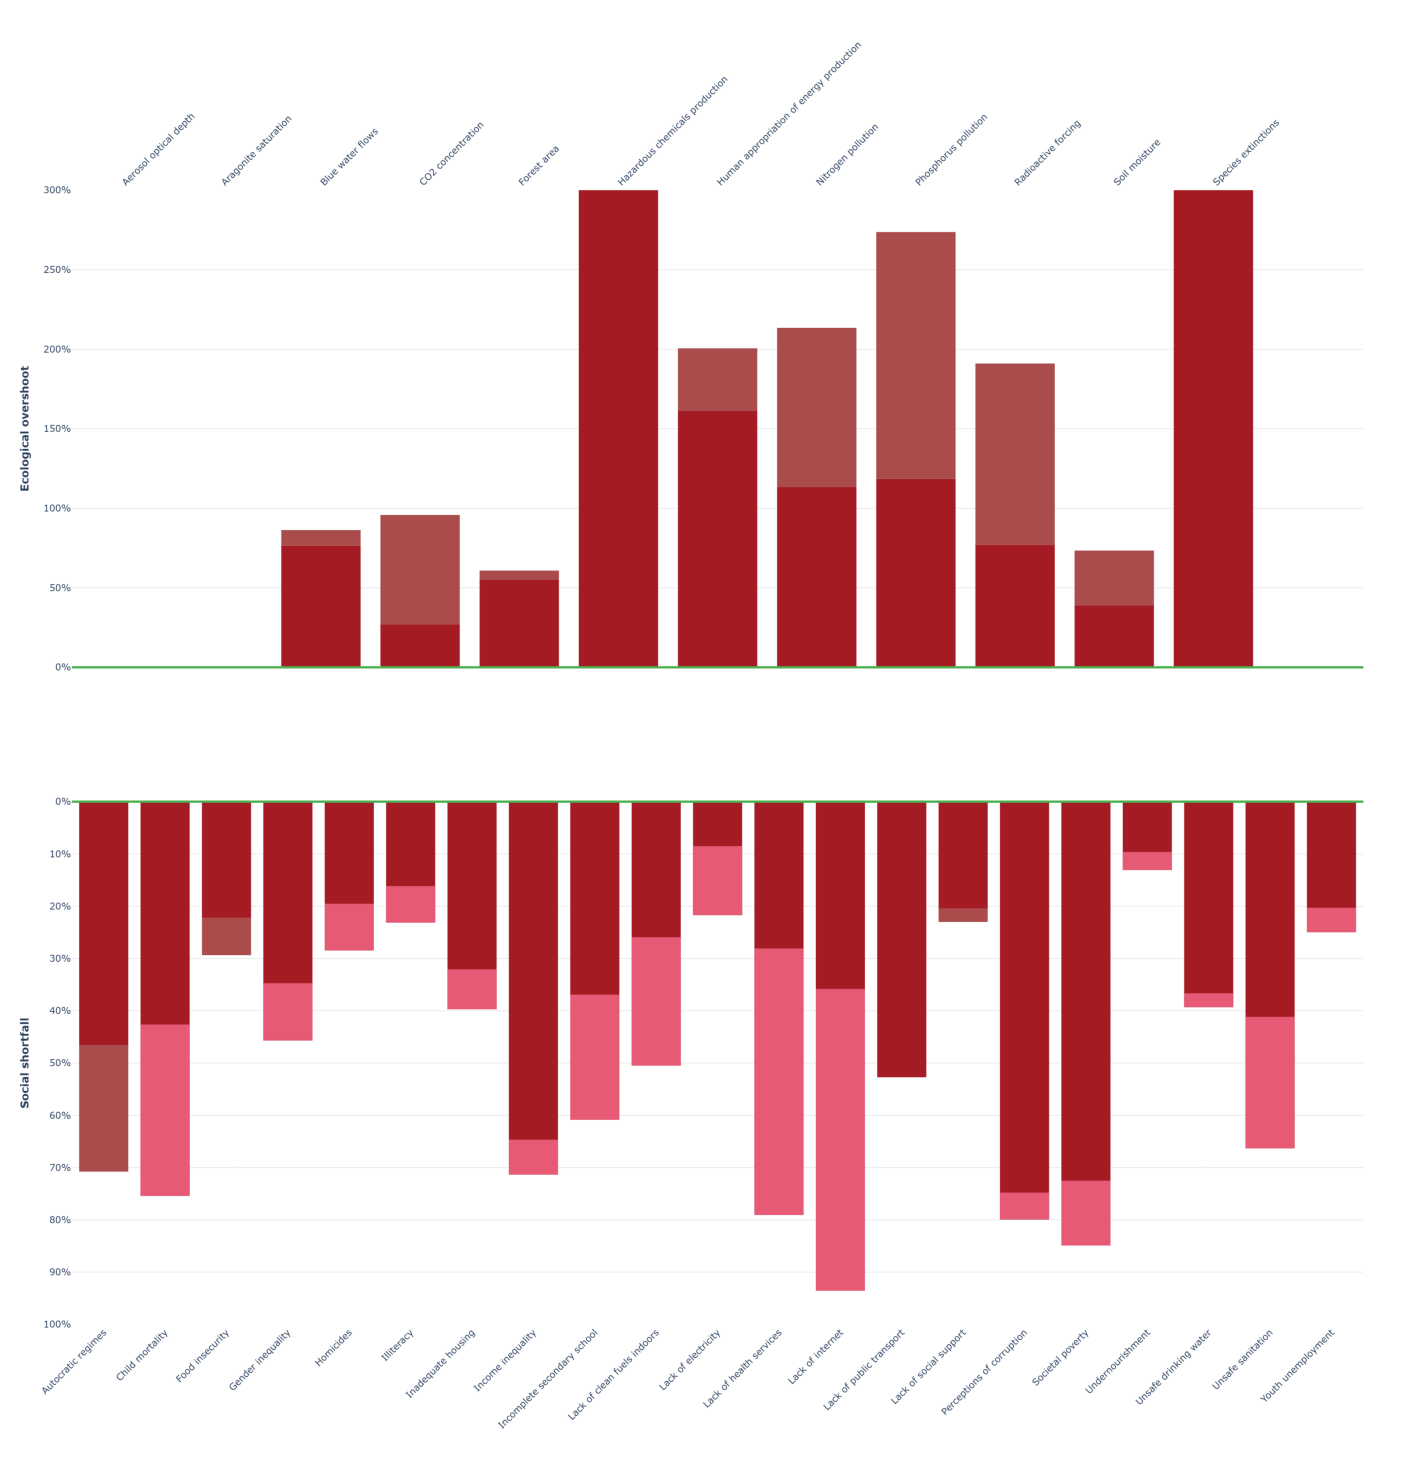

In [66]:
fig_eco.write_image("images/eco.png", width=1800, height=900, scale=2)
fig_social.write_image("images/social.png", width=1800, height=900, scale=2)

eco_img = mpimg.imread("images/eco.png")
social_img = mpimg.imread("images/social.png")
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 15),
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1, 1]}
)

axes[0].imshow(eco_img)
axes[0].axis('off')

axes[1].imshow(social_img)
axes[1].axis('off')

plt.show()

fig.savefig("outputs/7-sandwich.svg", format="svg", dpi=300, bbox_inches="tight")

### Doughnut Plot
* Finally after the sandwitch plot, we will proceed to the doughnut plot.
* What is a doughnut plot? It is a radial diagram that combines:
    * the **social foundation** (inner ring) showing the latest shortfall for each social indicator
    * the **ecological ceiling** (outer ring) showing the latest overshoot for each ecological indicator
* Obviously we will use the same tables as before

* Let's start slow
* We first have to define:
    * the radius of the green rings that structure the doughnut
    * the starting and ending radius for the social and ecological wedges
    * the color pallete used in the expected doughnut from the assignment

In [67]:
fig = go.Figure()

inner_dark_r = (0.38, 0.42)
middle_light_r = (0.42, 0.52)
outer_dark_r = (0.52, 0.56)

social_wedge_start_r = inner_dark_r[0]
eco_wedge_start_r = outer_dark_r[1]
eco_wedge_max_r = 1.1

dark_green = '#227443'   
light_green = '#6EB446'  

pink_darkest = '#672044'
pink_darker = '#AA446B'
pink_dark = '#DD788C'
pink_medium = '#E58493'
pink_light = '#F7AEB1'
pink_lightest = '#FFC6C4'

background_social = '#FFF5F0'
background_eco = '#FFFFFF'

* Okay, now we will define the frinedly names for the indicators and the order of the dimensions and its indicators for the doughnut.
* Based on these arrays it is determined how dimensions and indicators are arranged around the circle

In [68]:
eco_dimensions_config = [
    {'key': 'climate_change', 'label': 'climate\nchange', 'indicators': ['co2_ppm', 'erf_wm2']},
    {'key': 'ocean_acid', 'label': 'ocean\nacidification', 'indicators': ['omega_a']},
    {'key': 'chem_pollution', 'label': 'chemical\npollution', 'indicators': ['chemicalsMt']},
    {'key': 'nitrogen', 'label': 'nutrient\npollution', 'indicators': ['phosphorusMt', 'nitrogenMt']},
    {'key': 'aerosol', 'label': 'air\npollution', 'indicators': ['interhemAOD']},
    {'key': 'freshwater', 'label': 'freshwater\ndisruption', 'indicators': ['blueDev', 'soilDev']},
    {'key': 'land', 'label': 'land\nconversion', 'indicators': ['forestAreaMKM2']},
    {'key': 'biodiversity', 'label': 'biodiversity\nbreakdown', 'indicators': ['extinction1900', 'hanppGtC']},
    {'key': 'ozone', 'label': 'ozone\ndepletion', 'indicators': ['totalOzone']},
]

social_dimensions_config = [
    {'key': 'food', 'label': 'food', 'indicators': ['undernourishment', 'foodInsecurity']},
    {'key': 'health', 'label': 'health', 'indicators': ['under5death', 'UHCindex']},
    {'key': 'education', 'label': 'education', 'indicators': ['adultLiteracy', 'secondarySchool']},
    {'key': 'income_work', 'label': 'income\n& work', 'indicators': ['societalPoverty', 'youthNEET']},
    {'key': 'peace_justice', 'label': 'peace\n& justice', 'indicators': ['controlCorruption', 'homicideOver5']},
    {'key': 'political_voice', 'label': 'political\nvoice', 'indicators': ['govRegimes']},
    {'key': 'social_cohesion', 'label': 'social\ncohesion', 'indicators': ['socialSupport', 'palma']},
    {'key': 'equality', 'label': 'equality', 'indicators': ['genderGapIndex']},
    {'key': 'housing', 'label': 'housing', 'indicators': ['urbanSlums']},
    {'key': 'connectivity', 'label': 'connectivity', 'indicators': ['publicTrans', 'internet']},
    {'key': 'energy', 'label': 'energy', 'indicators': ['energyAccess', 'energyIndoor']},
    {'key': 'water', 'label': 'water', 'indicators': ['drinkingH2O', 'sanitation']},
]

* In order to extract the latest ecological overshoot and social shortfall from the tables, we will create helper functions.
* And also map the values to a color

In [69]:
def get_eco_overshoot_value(indicator_code):
    try:
        for idx in range(len(eco_progress_sorted)):
            row = eco_progress_sorted.iloc[idx]
            indicator_raw = row['indicator']
            indicator = str(indicator_raw.iloc[0] if isinstance(indicator_raw, pd.Series) else indicator_raw)

            if indicator == indicator_code:
                values_raw = row['value']
                if isinstance(values_raw, pd.Series):
                    last_value = float(values_raw.iloc[-1])
                elif isinstance(values_raw, dict):
                    last_value = float(values_raw['last'])
                else:
                    last_value = float(values_raw[-1]) if hasattr(values_raw, '__getitem__') else float(values_raw)

                overshoot = calculate_overshoot_percentage(last_value, indicator_code)
                return max(0, overshoot) if overshoot else 0
        return 0
    except Exception as e:
        print(f"Error getting overshoot for {indicator_code}: {e}")
        return 0

def get_shortfall_value(indicator_code):
    try:
        if 'social_progress_sorted' not in globals():
            return np.random.uniform(5, 70)
        for idx in range(len(social_progress_sorted)):
            row = social_progress_sorted.iloc[idx]
            indicator_raw = row['indicator']
            indicator = str(indicator_raw.iloc[0] if isinstance(indicator_raw, pd.Series) else indicator_raw)
            if indicator == indicator_code:
                values_raw = row['value']
                if isinstance(values_raw, pd.Series):
                    return float(values_raw.iloc[-1])
                elif isinstance(values_raw, dict):
                    return float(values_raw['last'])
                else:
                    return float(values_raw[-1]) if hasattr(values_raw, '__getitem__') else float(values_raw)
        return 0
    except Exception as e:
        return 0



* So, based on the values of the indicators, the color changes. 
* Let's create another two helpers to map the value to a color.

In [70]:
def get_social_color(shortfall):
    if shortfall > 60:
        return pink_darkest
    elif shortfall > 45:
        return pink_darker
    elif shortfall > 30:
        return pink_dark
    elif shortfall > 20:
        return pink_medium
    elif shortfall > 10:
        return pink_light
    else:
        return pink_lightest

def get_eco_color(overshoot):
    if overshoot > 500:
        return pink_darkest
    elif overshoot > 200:
        return pink_darker
    elif overshoot > 100:
        return pink_dark
    elif overshoot > 50:
        return pink_medium
    elif overshoot > 20:
        return pink_light
    else:
        return pink_lightest

* To actually draw the radial sectors we need some geometry helpers that:
    * generate polygon coordinates for a wedge between two radiuses and angles
    * and generate a filled ring between an inner and outer radius
* These functions are reused for both social and ecological layers

In [71]:
def create_wedge(r_inner, r_outer, theta_start, theta_end, n_points=30):
    theta_range = np.linspace(theta_start, theta_end, n_points)
    theta_rad = np.deg2rad(theta_range)
    
    x_outer = r_outer * np.cos(theta_rad)
    y_outer = r_outer * np.sin(theta_rad)
    
    if r_inner == 0:
        x_inner = [0]
        y_inner = [0]
    else:
        x_inner = r_inner * np.cos(theta_rad[::-1])
        y_inner = r_inner * np.sin(theta_rad[::-1])
    
    x = np.concatenate([x_outer, x_inner, [x_outer[0]]])
    y = np.concatenate([y_outer, y_inner, [y_outer[0]]])
    return x, y

def create_ring(r_inner, r_outer, theta_start=0, theta_end=360, n_points=100):
    theta_range = np.linspace(theta_start, theta_end, n_points)
    theta_rad = np.deg2rad(theta_range)
    
    x_outer = r_outer * np.cos(theta_rad)
    y_outer = r_outer * np.sin(theta_rad)
    x_inner = r_inner * np.cos(theta_rad[::-1])
    y_inner = r_inner * np.sin(theta_rad[::-1])
    
    x = np.concatenate([x_outer, x_inner, [x_outer[0]]])
    y = np.concatenate([y_outer, y_inner, [y_outer[0]]])
    return x, y

* Let's try to draw first the social indicators.
* We can add the easy part for sure which is to draw the pale background sectors for each social dimension on the inner part of the doughnut. 
* Each sector spans an angle proportional to the number of indicators belonging to that dimension

In [72]:
total_social_indicators = sum(len(dim['indicators']) for dim in social_dimensions_config)
angle_per_social_indicator = 360 / total_social_indicators

bg_current_angle = 90
for dim in social_dimensions_config:
    n_indicators_in_dim = len(dim['indicators'])
    dim_angle_span = n_indicators_in_dim * angle_per_social_indicator
    
    theta_start = bg_current_angle
    theta_end = bg_current_angle - dim_angle_span
    
    x_bg, y_bg = create_wedge(0, inner_dark_r[0], theta_end, theta_start, n_points=50)
    
    fig.add_trace(go.Scatter(
        x=x_bg, y=y_bg, fill='toself', fillcolor=background_social,
        line=dict(color='white', width=1.5),
        mode='lines', showlegend=False, hoverinfo='skip'
    ))
    bg_current_angle = theta_end


* Now we will repeat the same logic for the ecological dimensions but on the outer ring of the doughnut
* These sectors will have a neutral background on which the overshoot wedges will be drawn

In [73]:
total_eco_indicators = sum(len(dim['indicators']) for dim in eco_dimensions_config)
angle_per_eco_indicator = 360 / total_eco_indicators

bg_eco_angle = 90
for dim in eco_dimensions_config:
    n_indicators_in_dim = len(dim['indicators'])
    dim_angle_span = n_indicators_in_dim * angle_per_eco_indicator
    
    theta_start = bg_eco_angle
    theta_end = bg_eco_angle - dim_angle_span
    
    x_bg, y_bg = create_wedge(eco_wedge_start_r, eco_wedge_max_r, theta_end, theta_start, n_points=50)
    
    fig.add_trace(go.Scatter(
        x=x_bg, y=y_bg, fill='toself', fillcolor=background_eco,
        line=dict(color='white', width=1.5),
        mode='lines', showlegend=False, hoverinfo='skip'
    ))
    bg_eco_angle = theta_end

* Okay, for each social indicator we draw a wedge whose radial length encodes the latest shortfall:
* 0% shortfall means no wedge
* 100% shortfall means that the wedge fills the full height of the social ring
* The color of each wedge is chosen from the helper above

In [74]:
current_angle = 90
for dim in social_dimensions_config:
    for indicator_code in dim['indicators']:
        shortfall = get_shortfall_value(indicator_code)
        
        theta_start = current_angle
        theta_end = current_angle - angle_per_social_indicator
        
        normalized_shortfall = min(shortfall, 100) / 100.0
        r_outer = social_wedge_start_r
        r_inner_squared = r_outer**2 * (1 - normalized_shortfall)
        r_inner = np.sqrt(max(0, r_inner_squared))
        
        if normalized_shortfall > 0.01:
            x, y = create_wedge(r_inner, r_outer, theta_end, theta_start, n_points=30)
            
            color = get_social_color(shortfall)
            indicator_name = indicator_mapping.get(indicator_code, indicator_code) if 'indicator_mapping' in globals() else indicator_code
            
            fig.add_trace(go.Scatter(
                x=x, y=y, fill='toself', fillcolor=color,
                line=dict(color='white', width=0.5),
                mode='lines', showlegend=False,
                name=f"<b>{indicator_name}</b><br>{shortfall:.2f}%",
            ))
        
        current_angle = theta_end

* Now for the ecological wedges, for each indicator:
* the wedge grows outward from the ecological ring according to the latest overshoot percentage
* We will also apply a scaling factor so that extreme overshoots can be seen

In [75]:
eco_current_angle = 90

OVERSHOOT_DIVISOR = 5

for dim in eco_dimensions_config:
    for indicator_code in dim['indicators']:
        overshoot = get_eco_overshoot_value(indicator_code)
        
        theta_start = eco_current_angle
        theta_end = eco_current_angle - angle_per_eco_indicator
        
        if overshoot > 0.1:
            scaled_overshoot = overshoot / OVERSHOOT_DIVISOR
            normalized_overshoot = min(scaled_overshoot, 100) / 100.0
            
            r_inner = eco_wedge_start_r
            r_outer_squared = r_inner**2 + (eco_wedge_max_r**2 - r_inner**2) * normalized_overshoot
            r_outer = np.sqrt(r_outer_squared)
            
            x, y = create_wedge(r_inner, r_outer, theta_end, theta_start, n_points=30)
            color = get_eco_color(overshoot)
            indicator_name = eco_indicator_mapping.get(indicator_code, indicator_code)
            
            fig.add_trace(go.Scatter(
                x=x, y=y, fill='toself', fillcolor=color,
                line=dict(color='white', width=0.5),
                mode='lines', showlegend=False,
                name=f"<b>{indicator_name}</b><br>{(overshoot/100):.2f}%"
            ))
        
        eco_current_angle = theta_end


* The three green rings visually separate the central safe social foundation, the intermediate comfort zone and the ecological ceiling

In [76]:
x, y = create_ring(inner_dark_r[0], inner_dark_r[1])
_ = fig.add_trace(go.Scatter(x=x, y=y, fill='toself', fillcolor=dark_green,
    line=dict(color=dark_green, width=0), mode='lines', showlegend=False, hoverinfo='skip'))

x, y = create_ring(middle_light_r[0], middle_light_r[1])
_ = fig.add_trace(go.Scatter(x=x, y=y, fill='toself', fillcolor=light_green,
    line=dict(color=light_green, width=0), mode='lines', showlegend=False, hoverinfo='skip'))

x, y = create_ring(outer_dark_r[0], outer_dark_r[1])
_ = fig.add_trace(go.Scatter(x=x, y=y, fill='toself', fillcolor=dark_green,
    line=dict(color=dark_green, width=0), mode='lines', showlegend=False, hoverinfo='skip'))

* Finally, we can add the labels for each *social* and *ecological* dimension
* Also the curved text in the green rings

In [77]:
n_social = len(social_dimensions_config)
angle_per_social_dim = 360 / n_social

for i, dim in enumerate(social_dimensions_config):
    theta_center = 90 - (i + 0.5) * angle_per_social_dim
    theta_rad = np.deg2rad(theta_center)
    
    r_label = (middle_light_r[0] + middle_light_r[1]) / 2
    x_label = r_label * np.cos(theta_rad)
    y_label = r_label * np.sin(theta_rad)
    
    text_angle = theta_center - 90
    if y_label < 0:
        text_angle += 180
    
    fig.add_annotation(
        x=x_label, y=y_label, text=f"<b>{dim['label']}</b>",
        showarrow=False, font=dict(size=8, color='white', family='Arial'),
        textangle=text_angle, xanchor='center', yanchor='middle'
    )

n_eco = len(eco_dimensions_config)
angle_per_eco_dim = 360 / n_eco

for i, dim in enumerate(eco_dimensions_config):
    theta_center = 90 - (i + 0.5) * angle_per_eco_dim
    theta_rad = np.deg2rad(theta_center)
    
    r_label = eco_wedge_max_r + 0.12
    x_label = r_label * np.cos(theta_rad)
    y_label = r_label * np.sin(theta_rad)
    
    text_angle = theta_center - 90
    if y_label < 0:
        text_angle += 180
    
    fig.add_annotation(
        x=x_label, y=y_label, text=f"<b>{dim['label']}</b>",
        showarrow=False, font=dict(size=7, color='#333', family='Arial'),
        textangle=text_angle, xanchor='center', yanchor='middle'
    )

def add_curved_text(fig, text, r, start_angle, end_angle, font_size=8, color='white'):
    chars = list(text)
    n_chars = len(chars)
    angles = np.linspace(start_angle, end_angle, n_chars)
    
    for i, char in enumerate(chars):
        if char == ' ':
            continue
        theta_rad = np.deg2rad(angles[i])
        x = r * np.cos(theta_rad)
        y = r * np.sin(theta_rad)
        rotation = -angles[i] + 90
        
        fig.add_annotation(
            x=x, y=y, text=f"<b>{char}</b>", showarrow=False,
            font=dict(size=font_size, color=color, family='Arial'),
            textangle=rotation, xanchor='center', yanchor='middle'
        )

add_curved_text(fig, "SOCIAL FOUNDATION", r=(inner_dark_r[0] + inner_dark_r[1]) / 2,
                start_angle=150, end_angle=30, font_size=7)
add_curved_text(fig, "ECOLOGICAL CEILING", r=(outer_dark_r[0] + outer_dark_r[1]) / 2,
                start_angle=155, end_angle=25, font_size=7)

* Let's see what we built and export it as an svg file too.

In [78]:
fig.update_layout(
    xaxis=dict(visible=False, range=[-1.4, 1.4], scaleanchor='y', scaleratio=1),
    yaxis=dict(visible=False, range=[-1.4, 1.4]),
    width=900, height=900,
    plot_bgcolor='white', paper_bgcolor='white',
    showlegend=False,
    title=dict(text='<b>Doughnut of Social and Planetary Boundaries</b>', x=0.5, font=dict(size=16)),
    margin=dict(t=80, b=40, l=40, r=40),
    hoverlabel=dict(bgcolor="white", font_size=12, font_family="Arial")
)

fig.show()
fig.write_image("outputs/8-doughnut.svg")

### Doughnut Meaning
* If every measurement for every indicator was good, then we would have a perfect doughnut.
* The **Social** indicators represent the social foundation.
* Shortfalls here mean that people are falling into the hole of the doughnut, lacking life's essentials.
* The **Ecological** indicators represent the ecological ceiling.
* Overshoots here mean that humanity is putting too much pressure on the planet, exceeding its boundaries.

### Final Notes
* Some ecological indicators do not have the same overshoot like the expected result:
    * *Human appropriation of energy produced by plants* has an overshoot of 2.01% and the expected was 2.04%
    * *Hazardous chemicals production* has 36.93% and the expected was 32.15%
    * *Blue water flows* has 0.86% and the expected was 0.82% 
* The rest indicators are the same.
* When we hover the mouse to see the name and (overshoot / shortfall) % of the indicator, it appears twice and I don't know why...
* The dimensions shouldn't be like that.
* However, I believe that it is pretty close to the expected result.